# Aufgabe 2 – Model Baseline und Data Preparation

**Data Science WS 2026/27 | HdM** · Project Case „Air Quality Sensor Calibration“

**Forschungsfrage:** Lässt sich der PM2.5-Messwert eines hochwertigen Referenzgeräts (`pm25_target`) aus dem Messwert eines Low-Cost-Sensors (`pm25_lowcost`) zusammen mit weiteren Schadstoff- und Wettermessungen präzise schätzen?

**Ziele von Aufgabe 2**
1. **Baseline:** lineare Regression auf den Originaldaten mit minimaler Vorverarbeitung, bewertet auf dem Validierungsdatensatz (MAE und R²).
2. **Data Preparation:** die in Aufgabe 1 gefundenen Datenqualitätsprobleme Schritt für Schritt beheben (Plausibilität, Ausreißer, fehlende Werte, Transformation, Skalierung, Feature Selection).
3. **Effekt jedes Schritts messen:** nach jedem Schritt eine neue lineare Regression trainieren, auf der Validierung bewerten, Overfitting prüfen (Training vs. Validierung) und alles in einem Log-File dokumentieren.
4. **Finaler Test:** das beste Modell samt finaler Data Preparation einmalig auf die Testdaten anwenden.
5. **Export:** vorbereitete Trainings-, Validierungs- und Testdaten als CSV speichern (Grundlage für Aufgabe 3).

**Spielregeln, die wir im gesamten Notebook einhalten**
- In Validierungs- und Testdaten werden **keine Zeilen entfernt** und **keine Labels verändert**. Das prüfen wir nach jedem Schritt automatisch mit `assert`.
- Alle Parameter der Data Preparation (Grenzen, Mediane, Transformer, Scaler) werden **nur aus den Trainingsdaten gelernt** und danach unverändert auf Validierung und Test angewendet. Sonst würden Informationen aus den Bewertungsdaten in die Vorbereitung einfließen (Data Leakage) und die Ergebnisse wären zu optimistisch.
- Es werden nur Funktionen verwendet, die in den Python-Skripten des Kurses vorkommen.

**Gliederung**

| Teil | Abschnitte |
|---|---|
| A | 0 Setup & Anknüpfung an Aufgabe 1 · 1 Baseline · 2 Plausibilität · 3 Ausreißer · 4 Fehlende Werte |
| B | 5 Feature-Transformation · 6 Verteilungs-Transformation · 7 Skalierung · 8 Feature Selection · 9 Overfitting-Check & Gesamtübersicht · 10 Finaler Test · 11 Export & Learnings |

## 0 Setup und Anknüpfung an Aufgabe 1

### 0.1 Bibliotheken
Alle Importe stammen aus den Kurs-Notebooks (Missing Value Handling, Transformation, Scaling, Regression Analysis, Feature Selection).

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PowerTransformer, QuantileTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

### 0.2 Daten laden und Split wie in Aufgabe 1

Wir verwenden dieselben Dateien und denselben Split wie in Aufgabe 1. Alle Daten liegen im Ordner `src/Data/`:
- `pm25_train.csv`: 3.613 stündliche Messungen von Juni bis Oktober 2024
- `pm25_test.csv`: 1.464 stündliche Messungen von November bis Dezember 2024
- Trainingszeilen ohne Referenzwert (`pm25_target` fehlt) können weder zum Lernen noch zum Bewerten genutzt werden. Sie werden **vor** dem Split entfernt (das betrifft nur die Trainingsdatei).
- 80 % Training, 20 % Validierung mit `train_test_split(..., test_size=0.20, random_state=42)`.

Durch den identischen `random_state` landen exakt dieselben Zeilen in Training und Validierung wie in Aufgabe 1. Die Ergebnisse sind dadurch direkt vergleichbar.

In [2]:
LABEL = "pm25_target"
DATA_DIR = "../Data/"                   # Rohdaten und alle Ergebnisdateien liegen in src/Data
LOG_FILE = DATA_DIR + "task2_log.txt"

df = pd.read_csv(DATA_DIR + "pm25_train.csv")      # Original-Trainingsdaten (chronologisch sortiert)
test = pd.read_csv(DATA_DIR + "pm25_test.csv")     # offizielle Testdaten
print("Trainingsdatei:", df.shape, "| Testdatei:", test.shape)

# Split exakt wie in Aufgabe 1
labeled = df.dropna(subset=[LABEL]).copy()
print("Trainingszeilen ohne Label (vor dem Split entfernt):", len(df) - len(labeled))
train, valid = train_test_split(labeled, test_size=0.20, random_state=42)
print("Training:", len(train), "| Validierung:", len(valid), "| Test:", len(test))
print("Testzeilen ohne Label (bleiben im Datensatz, sind aber nicht bewertbar):", test[LABEL].isnull().sum())

Trainingsdatei: (3613, 17) | Testdatei: (1464, 17)
Trainingszeilen ohne Label (vor dem Split entfernt): 204
Training: 2727 | Validierung: 682 | Test: 1464
Testzeilen ohne Label (bleiben im Datensatz, sind aber nicht bewertbar): 45


### 0.3 Befunde aus Aufgabe 1 und abgeleitete Data-Preparation-Schritte

Die Reihenfolge der Schritte folgt den Befunden aus Aufgabe 1 und der Logik der Kurs-Pipelines (erst Ausreißer, dann Imputation, dann Transformation und Skalierung):

| Befund aus Aufgabe 1 | Konsequenz für Aufgabe 2 | Abschnitt |
|---|---|---|
| `no` hat negative Werte (Minimum −2,7). Konzentrationen können physikalisch nicht negativ sein. | Negative Konzentrationen auf 0 setzen | 2 |
| Viele IQR-Ausreißer: `no` 433, `glob_rad` 259, `pm25_lowcost` 238 (Max. 595,5 bei Median 2,7), `black_carbon` 211, `no2` 87, `ufp` 77, `co2` 28; im Label 98 | Ausreißer der Schadstoff-Features behandeln, Methoden vergleichen; Label-Ausreißer nur im Training | 3 |
| `pm25_lowcost` korreliert nur mit r = 0,08 mit dem Label, obwohl beide Geräte dieselbe Größe messen | Hinweis, dass Ausreißer den linearen Zusammenhang überdecken | 3, 6 |
| Fehlende Werte: `co2` 25,7 %, `ufp` 21,5 %, `o3` 20,7 %, `pm25_lowcost` 12,8 %, alle Wetter-Features 11,9 %, `pm25_target` 5,6 % | Imputationsstrategien vergleichen; Testzeilen dürfen nicht gelöscht werden | 4 |
| Histogramme zeigen stark rechtsschiefe Verteilungen (`no`, `pm25_lowcost`, `black_carbon`, `ufp`, `no2`) | Verteilungs-Transformation | 6 |
| Wertebereiche von ca. 0,04 (`black_carbon`) bis 110.000 (`ufp`) | Skalierung | 7 |
| Starke Korrelationen zwischen Features (z. B. `o3`–`relative_humidity` −0,81, `no`–`black_carbon` 0,71); in 1b verschlechterte `no2` das Modell | Feature Selection prüfen | 8 |
| In 1b war das Modell mit vielen Features auf den Testdaten schlechter als die Baseline | Unterschiede zwischen Trainings- und Testdaten untersuchen | 4, 10 |

Neue Erkenntnisse, die erst in Aufgabe 2 auffallen (z. B. `rain_vol` als kumulativer Zähler oder die vielen Lücken in den Testdaten), werden im jeweiligen Abschnitt begründet.

### 0.4 Hilfsfunktionen

Damit jeder Schritt gleich bewertet und dokumentiert wird, nutzen wir einige kleine Hilfsfunktionen:
- `feature_columns`: alle Spalten außer Label und Zeitspalten sind Features.
- `check_integrity`: prüft, dass Validierung und Test noch alle Zeilen haben und die Labels unverändert sind.
- `evaluate`: trainiert eine lineare Regression, berechnet MAE und R² auf Training und Validierung, die Veränderung gegenüber der Baseline (absolut und relativ) und schreibt alles in das Log-File `task2_log.txt`.
- `decide`: wendet unsere **Entscheidungsregel** an und schreibt die Entscheidung ins Log-File.

**Entscheidungsregel:** Ein Schritt bzw. eine Variante wird übernommen, wenn der **MAE auf der Validierung sinkt und R² auf der Validierung nicht schlechter wird.** Gibt es mehrere Varianten, gewinnt die beste. Wir verlangen beide Kennzahlen, damit ein Schritt nicht nur eine Kennzahl auf Kosten der anderen verbessert.

Jeder Schritt wird zweimal bewertet:
- **kumulativ:** auf dem bisher besten Stand (so entsteht schrittweise die finale Data Preparation),
- **isoliert:** nur dieser Schritt auf den Originaldaten der Baseline (so sieht man den Effekt des Schritts für sich allein).

In [3]:
def feature_columns(data):
    """Alle Spalten außer Label und Zeitspalten sind Features."""
    return [col for col in data.columns if col not in [LABEL, "timestamp", "year_month"]]


# Referenzwerte, um nach jedem Schritt zu prüfen, dass Validierung und Test unverändert bleiben
VAL_LABEL_ORIGINAL = valid[LABEL].copy()
TEST_LABEL_ORIGINAL = test[LABEL].copy()


def check_integrity(val_df, test_df):
    """Validierung und Test: keine Zeile entfernt, Reihenfolge gleich, kein Label verändert."""
    for data, original, name in [(val_df, VAL_LABEL_ORIGINAL, "Validierung"), (test_df, TEST_LABEL_ORIGINAL, "Test")]:
        assert len(data) == len(original), "Es wurden Zeilen entfernt: " + name
        assert (data.index == original.index).sum() == len(original), "Zeilen wurden verändert: " + name
        assert (data[LABEL] - original).abs().sum() == 0, "Labels wurden verändert: " + name
        assert data[LABEL].isnull().sum() == original.isnull().sum(), "Labels wurden verändert: " + name
    print("Integritätsprüfung bestanden: Validierung", len(val_df), "Zeilen, Test", len(test_df), "Zeilen, Labels unverändert.")


# Log-File neu anlegen (Modus 'w'), danach wird nur noch angehängt (Modus 'a')
with open(LOG_FILE, "w", encoding="utf-8") as log:
    log.write("Log Aufgabe 2 - Data Preparation, Modell: lineare Regression\n")
    log.write("Split wie Aufgabe 1: dropna(Label), train_test_split(test_size=0.20, random_state=42)\n")
    log.write("Spalten: Schritt | Art | Beschreibung (was wurde angepasst) | Zeilen Train | Anzahl Features | "
              "MAE Train | MAE Val | R2 Train | R2 Val | dMAE Val vs. Baseline\n")

results = []      # alle Experimente (für Tabellen und Diagramme)
BASELINE = {}     # wird in Abschnitt 1 gefüllt


def evaluate(step_id, art, beschreibung, train_df, val_df):
    """Trainiert eine lineare Regression auf train_df und bewertet sie auf Training und Validierung.
    Das Ergebnis wird in `results` gespeichert und als Zeile ins Log-File geschrieben."""
    features = feature_columns(train_df)
    X_train = train_df[features]
    X_val = val_df[features]
    # Minimal-Vorverarbeitung: noch vorhandene Fehlwerte mit dem Trainings-Median füllen,
    # weil LinearRegression keine NaN verarbeiten kann
    median = X_train.median()
    X_train = X_train.fillna(median)
    X_val = X_val.fillna(median)

    reg = linear_model.LinearRegression()
    reg.fit(X_train, train_df[LABEL])

    row = {"Schritt": step_id, "Art": art, "Beschreibung": beschreibung,
           "Zeilen_Train": len(train_df), "Features": len(features),
           "MAE_Train": mean_absolute_error(train_df[LABEL], reg.predict(X_train)),
           "MAE_Val": mean_absolute_error(val_df[LABEL], reg.predict(X_val)),
           "R2_Train": reg.score(X_train, train_df[LABEL]),
           "R2_Val": reg.score(X_val, val_df[LABEL])}
    if BASELINE:
        # Veränderung gegenüber der Baseline: negativ beim MAE = besser, positiv bei R² = besser
        row["dMAE_abs"] = row["MAE_Val"] - BASELINE["MAE_Val"]
        row["dMAE_rel_%"] = row["dMAE_abs"] / BASELINE["MAE_Val"] * 100
        row["dR2_abs"] = row["R2_Val"] - BASELINE["R2_Val"]
        row["dR2_rel_%"] = row["dR2_abs"] / BASELINE["R2_Val"] * 100
        delta = row["dMAE_abs"]
    else:
        delta = 0.0
    results.append(row)

    with open(LOG_FILE, "a", encoding="utf-8") as log:
        log.write(f"{step_id} | {art} | {beschreibung} | {len(train_df)} | {len(features)} | "
                  f"{row['MAE_Train']:.4f} | {row['MAE_Val']:.4f} | {row['R2_Train']:.4f} | "
                  f"{row['R2_Val']:.4f} | {delta:+.4f}\n")
    return row


def show(rows):
    """Zeigt Experimente als gerundete Tabelle."""
    return pd.DataFrame(rows).round(4)


def decide(step, current, candidates):
    """Entscheidungsregel: Val-MAE muss sinken UND Val-R² darf nicht schlechter werden.
    Gibt das Ergebnis (row) der besten Variante zurück, sonst den bisherigen Stand."""
    best = current
    for row in candidates:
        if row["MAE_Val"] < best["MAE_Val"] and row["R2_Val"] >= best["R2_Val"]:
            best = row
    if best is current:
        text = (f"ENTSCHEIDUNG {step}: keine Variante übernommen, bisheriger Stand bleibt "
                f"(MAE Val {current['MAE_Val']:.4f}, R2 Val {current['R2_Val']:.4f})")
    else:
        text = (f"ENTSCHEIDUNG {step}: übernommen wird {best['Schritt']} '{best['Beschreibung']}' "
                f"(MAE Val {current['MAE_Val']:.4f} -> {best['MAE_Val']:.4f}, "
                f"R2 Val {current['R2_Val']:.4f} -> {best['R2_Val']:.4f})")
    print(text)
    with open(LOG_FILE, "a", encoding="utf-8") as log:
        log.write(text + "\n")
    return best

## 1 Baseline mit minimaler Vorverarbeitung

Die Baseline nutzt die Originaldaten mit so wenig Vorverarbeitung wie möglich:
- Als Features dienen alle 14 numerischen Spalten. `timestamp` und `year_month` sind Text und können von der linearen Regression nicht direkt verarbeitet werden.
- Fehlende Feature-Werte werden mit dem Median der Trainingsdaten ersetzt. Das ist das Minimum, weil `LinearRegression` keine NaN verarbeiten kann.

Alle weiteren Schritte werden an dieser Baseline gemessen.

In [4]:
print("Features der Baseline:", feature_columns(train))
baseline_row = evaluate("1", "Baseline", "Originaldaten, 14 numerische Features, NaN -> Trainings-Median", train, valid)
BASELINE = baseline_row

# Ausgangspunkt für die schrittweise Data Preparation
train_cur, valid_cur, test_cur = train.copy(), valid.copy(), test.copy()
current = baseline_row
path = [baseline_row]          # Weg der übernommenen Schritte (für Overfitting-Check und Diagramme)
show([baseline_row])

Features der Baseline: ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad']


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val
0,1,Baseline,"Originaldaten, 14 numerische Features, NaN -> ...",2727,14,1.3261,1.3417,0.3183,0.359


**Interpretation:**
- Die Baseline erreicht auf der Validierung einen MAE von 1,342 µg/m³ und ein R² von 0,359. Das ist exakt das Ergebnis des Modells mit allen Features aus Aufgabe 1b. Der Split ist also korrekt reproduziert.
- Ein MAE von 1,34 µg/m³ ist bei einem mittleren Referenzwert von 3,3 µg/m³ sehr hoch (rund 40 %). Das Modell erklärt nur gut ein Drittel der Varianz.
- Training (MAE 1,326) und Validierung (MAE 1,342) liegen nah beieinander. Das Modell ist also nicht überangepasst, sondern eher zu schwach (Underfitting). Der Grund liegt in den Daten: Die Ausreißer und Lücken aus Aufgabe 1 überdecken den eigentlich engen Zusammenhang zwischen Low-Cost-Sensor und Referenzgerät.

## 2 Plausibilität: negative Konzentrationen

**Begründung:** In Aufgabe 1 hatte `no` negative Werte (Minimum −2,7). Eine Konzentration kann physikalisch nicht negativ sein. Solche Werte entstehen durch Messrauschen bzw. Nullpunktdrift der Analysegeräte bei sehr niedrigen Konzentrationen. Wir prüfen alle Konzentrations-Features in allen drei Datensätzen.

**Vorgehen:** Negative Werte werden auf 0 gesetzt (`clip(lower=0)`, aus dem Kurs-Skript zu Exponential Smoothing). Das betrifft nur Features, nie das Label, und es wird keine Zeile entfernt.

In [5]:
CONC_COLS = ["pm25_lowcost", "no", "no2", "o3", "co2", "black_carbon", "ufp"]

negative_counts = pd.DataFrame({"Training": (train[CONC_COLS] < 0).sum(),
                                "Validierung": (valid[CONC_COLS] < 0).sum(),
                                "Test": (test[CONC_COLS] < 0).sum()})
negative_counts

,Training,Validierung,Test
pm25_lowcost,0,0,0
no,376,86,99
no2,0,0,0
o3,0,0,142
co2,0,0,0
black_carbon,0,0,0
ufp,0,0,0


In [6]:
def clip_negative(train_df, val_df, test_df, columns):
    """Setzt negative Konzentrationen auf 0 (nur Features, nie das Label)."""
    result = []
    for data in [train_df, val_df, test_df]:
        data = data.copy()
        for col in columns:
            data[col] = data[col].clip(lower=0)
        result.append(data)
    return result[0], result[1], result[2]


tr2, va2, te2 = clip_negative(train_cur, valid_cur, test_cur, CONC_COLS)
check_integrity(va2, te2)
# Da wir noch auf der Baseline stehen, ist kumulativ hier gleich isoliert
r2 = evaluate("2", "kumulativ", "negative Konzentrationen auf 0 gesetzt (clip)", tr2, va2)
show([current, r2])

Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,1,Baseline,"Originaldaten, 14 numerische Features, NaN -> ...",2727,14,1.3261,1.3417,0.3183,0.3590,NaN,NaN,NaN,NaN
1,2,kumulativ,negative Konzentrationen auf 0 gesetzt (clip),2727,14,1.3257,1.3412,0.3186,0.3594,-0.0005,-0.0382,0.0004,0.1046


In [7]:
best = decide("Schritt 2 (Plausibilität)", current, [r2])
if best is not current:
    train_cur, valid_cur, test_cur = tr2, va2, te2
    current = best
    path.append(best)

ENTSCHEIDUNG Schritt 2 (Plausibilität): übernommen wird 2 'negative Konzentrationen auf 0 gesetzt (clip)' (MAE Val 1.3417 -> 1.3412, R2 Val 0.3590 -> 0.3594)


**Interpretation:**
- Negative Werte gibt es bei `no` in allen drei Datensätzen (Training 376, Validierung 86, Test 99) und bei `o3` nur im Test (142). Sie liegen alle knapp unter 0 (Minimum −2,7).
- Der Effekt auf das Modell ist minimal (MAE −0,0005, R² +0,0004), weil die Werte ohnehin nahe 0 liegen. Der Schritt wird trotzdem übernommen: Er beseitigt physikalisch unmögliche Werte. Das ist besonders für die Testdaten wichtig, in denen `o3` sonst Werte unterhalb des gesamten Trainingsbereichs hätte.

## 3 Ausreißer

**Begründung (Aufgabe 1):** Die IQR-Regel zeigte viele Ausreißer, besonders bei `no` (433), `pm25_lowcost` (238), `black_carbon` (211), `no2` (87), `ufp` (77) und `co2` (28). `pm25_lowcost` erreicht 595,5 µg/m³, während der Median bei 2,7 liegt. Die lineare Regression minimiert quadrierte Fehler und wird von solchen Extremwerten stark beeinflusst.

**Welche Spalten?** Wir behandeln nur die Schadstoff-Features. Die IQR-„Ausreißer“ bei den Wetter-Features sind echte Wetterlagen (z. B. Tiefdruck, Sturm) und bei `glob_rad` die hellen Mittagsstunden neben vielen Nacht-Nullen. Das sind keine Messfehler, deshalb bleiben sie unverändert. Die Label-Ausreißer (98) dürfen wir in Validierung und Test nicht anfassen. Wir testen nur, ob es hilft, sie aus den **Trainingsdaten** zu entfernen (Instance Selection).

**Warum vor der Imputation?** Mittelwerte und Regressionen, mit denen später fehlende Werte ersetzt werden, sollen nicht von Ausreißern verzerrt werden. Die Kurs-Pipelines haben dieselbe Reihenfolge (OutlierRemover → Imputer → Scaler).

Zuerst ein Blick auf den wichtigsten Zusammenhang: Low-Cost-Sensor gegen Referenzgerät, eingefärbt nach Luftfeuchte.

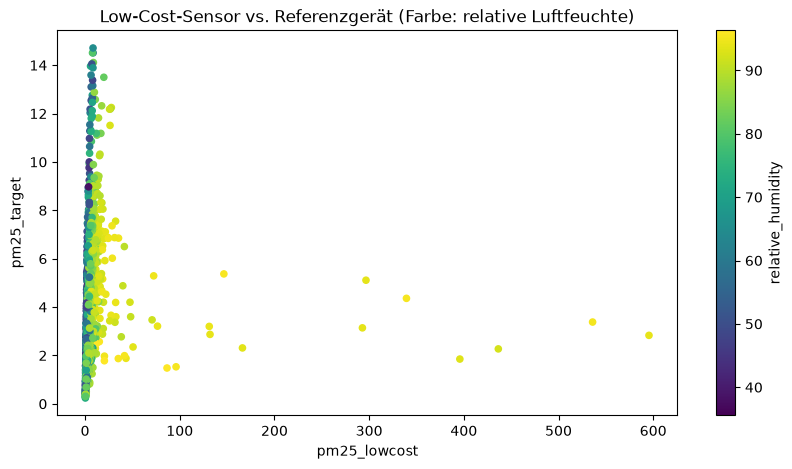

Obere IQR-Grenze pm25_lowcost: 9.69 µg/m³
Mittlere Luftfeuchte bei Low-Cost-Ausreißern: 90.8 %
Mittlere Luftfeuchte bei allen anderen Werten: 73.0 %
Mittleres Label bei Low-Cost-Ausreißern: 5.78 µg/m³ (sonst 3.15 µg/m³)


In [8]:
OUTLIER_COLS = ["pm25_lowcost", "no", "no2", "black_carbon", "ufp", "co2"]

train_cur.plot.scatter(x="pm25_lowcost", y=LABEL, c="relative_humidity", colormap="viridis",
                       sharex=False, figsize=(10, 5), title="Low-Cost-Sensor vs. Referenzgerät (Farbe: relative Luftfeuchte)")
plt.show()

# Wann treten die extremen Low-Cost-Werte auf?
q1, q3 = train_cur["pm25_lowcost"].quantile(0.25), train_cur["pm25_lowcost"].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
is_high = train_cur["pm25_lowcost"] > upper_fence
print(f"Obere IQR-Grenze pm25_lowcost: {upper_fence:.2f} µg/m³")
print(f"Mittlere Luftfeuchte bei Low-Cost-Ausreißern: {train_cur.loc[is_high, 'relative_humidity'].mean():.1f} %")
print(f"Mittlere Luftfeuchte bei allen anderen Werten: {train_cur.loc[~is_high, 'relative_humidity'].mean():.1f} %")
print(f"Mittleres Label bei Low-Cost-Ausreißern: {train_cur.loc[is_high, LABEL].mean():.2f} µg/m³ "
      f"(sonst {train_cur.loc[~is_high, LABEL].mean():.2f} µg/m³)")

**Beobachtung:** Für den Großteil der Messungen ist der Zusammenhang eng (fast senkrechte Punktwolke links). Die extremen Low-Cost-Werte bis fast 600 µg/m³ treten aber fast nur bei sehr hoher Luftfeuchte auf (gelbe Punkte, im Mittel 90,8 % gegenüber 73,0 %). Das Referenzgerät misst in diesen Stunden nur leicht erhöhte Werte (im Mittel 5,8 statt 3,2 µg/m³). Das passt zum Messprinzip: Optische Low-Cost-Sensoren zählen Partikel, die bei hoher Feuchte Wasser aufnehmen und dadurch größer erscheinen. Referenzgeräte trocknen die Luftprobe in der Regel vor der Messung. Die Ausreißer sind also überwiegend **Messartefakte** und keine echten Feinstaubspitzen. Diese Erkenntnis nutzen wir in Abschnitt 5 erneut.

**Varianten**, die wir vergleichen (alle Grenzen werden **nur aus den Trainingsdaten** berechnet):

| Variante | Methode | Vorlage im Kurs |
|---|---|---|
| 3a | IQR-Regel: Ausreißer werden zu NaN und anschließend imputiert | `OutlierRemover(method='iqr')`, Pipeline_Demo2 |
| 3b | 3-Sigma-Regel: Ausreißer werden zu NaN und anschließend imputiert | `remove_outliers`, Pipeline_Lab1 |
| 3c | IQR-Regel erkennt Ausreißer, Ersatz durch das 5. bzw. 95. Perzentil | `OutlierRemover(5, 95)`, Pipeline_Lab2 |
| 3d | Kappen (Winsorizing) aller Werte am 1. und 99. Perzentil | `quantile`, `clip` |
| 3e | Kappen (Winsorizing) aller Werte am 5. und 95. Perzentil | `quantile`, `clip` |
| 3f | zusätzlich nur im Training: Zeilen mit Label-Ausreißern entfernen | Instance Selection |

**Wichtiger Unterschied zu den Kurs-Klassen:** Deren `transform()` berechnet die Grenzen jedes Mal neu aus den übergebenen Daten. Auf den Testdaten würden die Testdaten dann ihre eigenen Grenzen bestimmen. Wir lernen die Grenzen deshalb einmal auf den Trainingsdaten und wenden sie auf alle drei Datensätze an.

In [9]:
def handle_outliers(train_df, val_df, test_df, columns, method, lower_q=0.05, upper_q=0.95):
    """Behandelt Ausreißer in `columns`. Alle Grenzen werden NUR aus den Trainingsdaten gelernt
    und dann auf Training, Validierung und Test angewendet. Es wird keine Zeile entfernt."""
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    for col in columns:
        # Kennzahlen ausschließlich aus den Trainingsdaten
        q1 = train_df[col].quantile(0.25)
        q3 = train_df[col].quantile(0.75)
        iqr = q3 - q1
        mean = train_df[col].mean()
        std = train_df[col].std()
        p_low = train_df[col].quantile(lower_q)
        p_high = train_df[col].quantile(upper_q)
        for data in [train_df, val_df, test_df]:
            if method == "iqr_nan":            # Variante 3a
                is_outlier = (data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)
                data[col] = np.where(is_outlier, np.nan, data[col])
            elif method == "sigma_nan":        # Variante 3b
                is_outlier = (data[col] < mean - 3 * std) | (data[col] > mean + 3 * std)
                data[col] = np.where(is_outlier, np.nan, data[col])
            elif method == "iqr_percentile":   # Variante 3c (Kurs-Muster Pipeline_Lab2)
                data[col] = np.where(data[col] < q1 - 1.5 * iqr, p_low, data[col])
                data[col] = np.where(data[col] > q3 + 1.5 * iqr, p_high, data[col])
            elif method == "clip":             # Varianten 3d und 3e
                data[col] = data[col].clip(lower=p_low, upper=p_high)
    return train_df, val_df, test_df


outlier_variants = {
    "3a": ("IQR-Regel -> NaN (danach Median)", "iqr_nan", 0.05, 0.95),
    "3b": ("3-Sigma-Regel -> NaN (danach Median)", "sigma_nan", 0.05, 0.95),
    "3c": ("IQR-Erkennung, Ersatz durch 5./95. Perzentil", "iqr_percentile", 0.05, 0.95),
    "3d": ("Kappen am 1./99. Perzentil", "clip", 0.01, 0.99),
    "3e": ("Kappen am 5./95. Perzentil", "clip", 0.05, 0.95),
}

variants = {}            # Datensätze je Variante, damit die beste übernommen werden kann
rows_cum, rows_iso = [], []
for step_id in outlier_variants:
    text, method, lower_q, upper_q = outlier_variants[step_id]
    # kumulativ: auf dem bisherigen Stand
    tr, va, te = handle_outliers(train_cur, valid_cur, test_cur, OUTLIER_COLS, method, lower_q, upper_q)
    check_integrity(va, te)
    variants[step_id] = (tr, va, te)
    rows_cum.append(evaluate(step_id, "kumulativ", "Ausreißer: " + text, tr, va))
    # isoliert: nur dieser Schritt auf den Originaldaten
    tr, va, te = handle_outliers(train, valid, test, OUTLIER_COLS, method, lower_q, upper_q)
    rows_iso.append(evaluate(step_id, "isoliert", "Ausreißer: " + text, tr, va))

show([current] + rows_cum + rows_iso)

Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,2,kumulativ,negative Konzentrationen auf 0 gesetzt (clip),2727,14,1.3257,1.3412,0.3186,0.3594,-0.0005,-0.0382,0.0004,0.1046
1,3a,kumulativ,Ausreißer: IQR-Regel -> NaN (danach Median),2727,14,0.9877,1.0064,0.5342,0.5643,-0.3353,-24.9892,0.2053,57.1744
2,3b,kumulativ,Ausreißer: 3-Sigma-Regel -> NaN (danach Median),2727,14,1.0790,1.1133,0.4768,0.4622,-0.2284,-17.0257,0.1032,28.7346
3,3c,kumulativ,"Ausreißer: IQR-Erkennung, Ersatz durch 5./95. ...",2727,14,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,91.0677
4,3d,kumulativ,Ausreißer: Kappen am 1./99. Perzentil,2727,14,1.0707,1.0919,0.4893,0.5122,-0.2498,-18.6215,0.1531,42.6442
5,3e,kumulativ,Ausreißer: Kappen am 5./95. Perzentil,2727,14,0.8546,0.8797,0.6917,0.6835,-0.4620,-34.4351,0.3245,90.3665
6,3a,isoliert,Ausreißer: IQR-Regel -> NaN (danach Median),2727,14,0.9884,1.0075,0.5339,0.5635,-0.3342,-24.9119,0.2044,56.9332
7,3b,isoliert,Ausreißer: 3-Sigma-Regel -> NaN (danach Median),2727,14,1.0793,1.1135,0.4767,0.4623,-0.2282,-17.0112,0.1032,28.7557
8,3c,isoliert,"Ausreißer: IQR-Erkennung, Ersatz durch 5./95. ...",2727,14,0.8637,0.8754,0.6861,0.6856,-0.4663,-34.7523,0.3266,90.9563
9,3d,isoliert,Ausreißer: Kappen am 1./99. Perzentil,2727,14,1.0717,1.0929,0.4887,0.5116,-0.2488,-18.5468,0.1525,42.4799


ENTSCHEIDUNG Schritt 3 (Ausreißer): übernommen wird 3c 'Ausreißer: IQR-Erkennung, Ersatz durch 5./95. Perzentil' (MAE Val 1.3412 -> 0.8751, R2 Val 0.3594 -> 0.6860)
Anzahl und Anteil veränderter Werte je Spalte:
              Training  Validierung  Test  Training %  Validierung %  Test %
pm25_lowcost       190           43   344         7.0            6.3    23.5
no                 313           73   283        11.5           10.7    19.3
no2                 67           23    37         2.5            3.4     2.5
black_carbon       174           45    81         6.4            6.6     5.5
ufp                 58           21     1         2.1            3.1     0.1
co2                 23            4    13         0.8            0.6     0.9


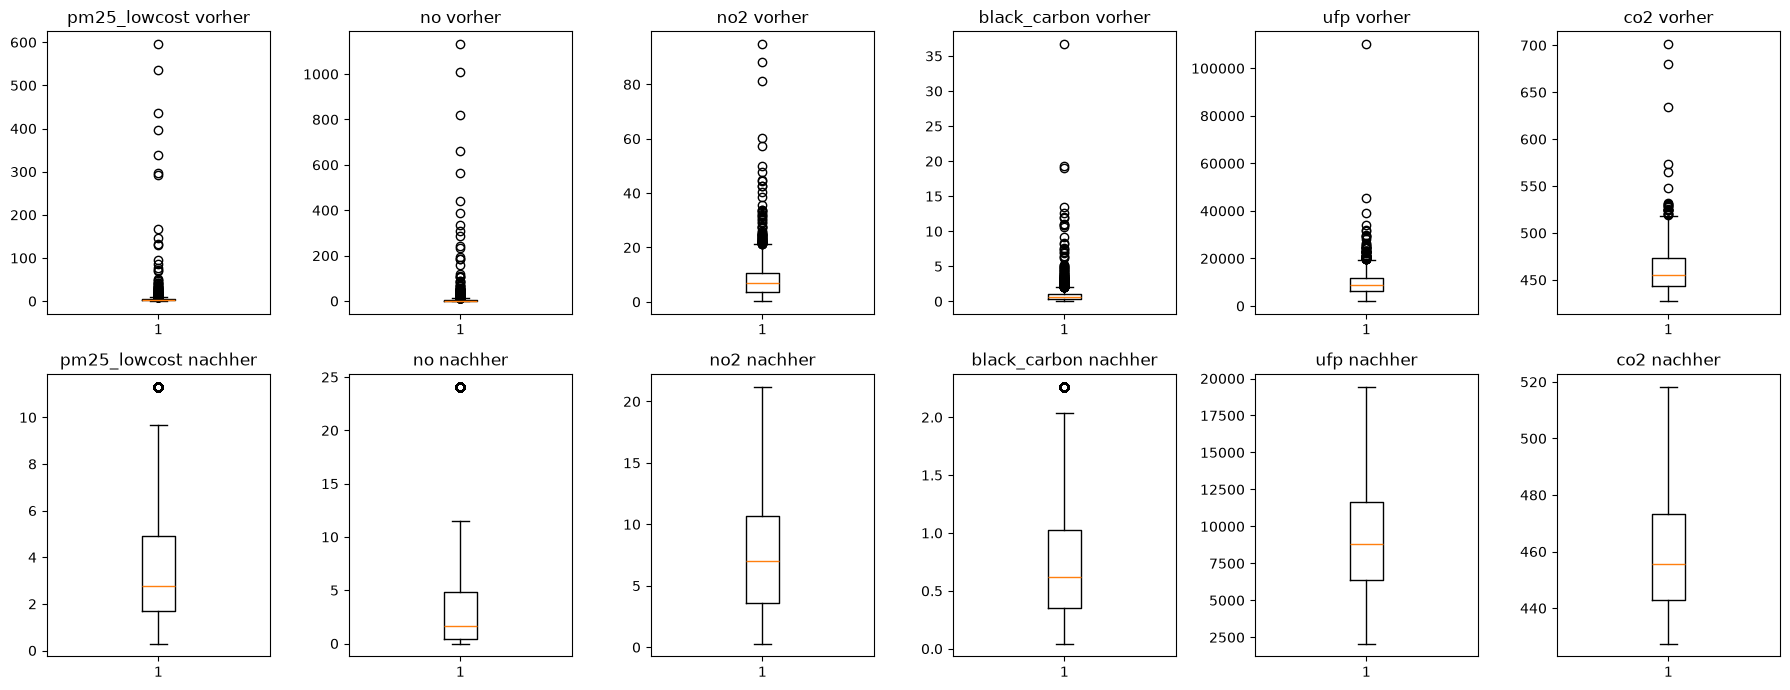

In [10]:
best = decide("Schritt 3 (Ausreißer)", current, rows_cum)
if best is not current:
    train_before_outliers, valid_before_outliers, test_before_outliers = train_cur, valid_cur, test_cur
    train_cur, valid_cur, test_cur = variants[best["Schritt"]]
    current = best
    path.append(best)

    # Wie viele Werte wurden je Spalte verändert?
    changed = pd.DataFrame({
        "Training": ((train_before_outliers[OUTLIER_COLS] != train_cur[OUTLIER_COLS]) & train_before_outliers[OUTLIER_COLS].notnull()).sum(),
        "Validierung": ((valid_before_outliers[OUTLIER_COLS] != valid_cur[OUTLIER_COLS]) & valid_before_outliers[OUTLIER_COLS].notnull()).sum(),
        "Test": ((test_before_outliers[OUTLIER_COLS] != test_cur[OUTLIER_COLS]) & test_before_outliers[OUTLIER_COLS].notnull()).sum()})
    changed["Training %"] = (changed["Training"] / len(train_cur) * 100).round(1)
    changed["Validierung %"] = (changed["Validierung"] / len(valid_cur) * 100).round(1)
    changed["Test %"] = (changed["Test"] / len(test_cur) * 100).round(1)
    print("Anzahl und Anteil veränderter Werte je Spalte:")
    print(changed)

    # Boxplots vorher (oben) und nachher (unten), Trainingsdaten
    fig, axs = plt.subplots(2, len(OUTLIER_COLS), figsize=(18, 7))
    for i in range(len(OUTLIER_COLS)):
        col = OUTLIER_COLS[i]
        axs[0, i].boxplot(train_before_outliers[col].dropna())
        axs[0, i].set_title(col + " vorher")
        axs[1, i].boxplot(train_cur[col].dropna())
        axs[1, i].set_title(col + " nachher")
    plt.tight_layout()
    plt.show()

**Variante 3f – Label-Ausreißer nur im Training entfernen:** Die 98 Label-Ausreißer aus Aufgabe 1 sind hohe, aber plausible Feinstaubwerte. Wir prüfen trotzdem, ob das Modell besser generalisiert, wenn diese Zeilen nur aus dem **Training** entfernt werden. In Validierung und Test bleiben alle Zeilen erhalten.

In [11]:
def remove_label_outliers(train_df):
    """Instance Selection: entfernt Trainingszeilen, deren Label über der oberen IQR-Grenze liegt."""
    q1 = train_df[LABEL].quantile(0.25)
    q3 = train_df[LABEL].quantile(0.75)
    upper = q3 + 1.5 * (q3 - q1)
    print(f"Obere IQR-Grenze des Labels: {upper:.2f} µg/m³ -> {(train_df[LABEL] > upper).sum()} Trainingszeilen entfernt")
    return train_df[train_df[LABEL] <= upper].copy()


tr3f = remove_label_outliers(train_cur)
r3f = evaluate("3f", "kumulativ", "nur Training: Zeilen mit Label-Ausreißern (IQR) entfernt", tr3f, valid_cur)
r3f_iso = evaluate("3f", "isoliert", "nur Training: Zeilen mit Label-Ausreißern (IQR) entfernt", remove_label_outliers(train), valid)
show([current, r3f, r3f_iso])

Obere IQR-Grenze des Labels: 8.53 µg/m³ -> 77 Trainingszeilen entfernt
Obere IQR-Grenze des Labels: 8.53 µg/m³ -> 77 Trainingszeilen entfernt


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,3c,kumulativ,"Ausreißer: IQR-Erkennung, Ersatz durch 5./95. ...",2727,14,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,91.0677
1,3f,kumulativ,nur Training: Zeilen mit Label-Ausreißern (IQR...,2650,14,0.7541,0.8794,0.6693,0.6546,-0.4623,-34.4582,0.2956,82.3161
2,3f,isoliert,nur Training: Zeilen mit Label-Ausreißern (IQR...,2650,14,1.1501,1.3343,0.3308,0.3076,-0.0074,-0.5491,-0.0515,-14.3399


In [12]:
best = decide("Schritt 3f (Label-Ausreißer im Training)", current, [r3f])
if best is not current:
    train_cur = tr3f
    current = best
    path.append(best)

ENTSCHEIDUNG Schritt 3f (Label-Ausreißer im Training): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.8751, R2 Val 0.6860)


**Interpretation:**
- **Die Ausreißerbehandlung ist der wichtigste Einzelschritt:** Mit Variante 3c sinkt der Validierungs-MAE von 1,341 auf 0,875 (−34,8 % ggü. Baseline), R² steigt von 0,36 auf 0,69. Die Korrelation zwischen `pm25_lowcost` und Label steigt dadurch von 0,08 auf 0,61 (siehe Abschnitt 8).
- **Ersetzen schlägt Löschen:** Die Varianten, die Ausreißer durch einen Perzentilwert ersetzen (3c, 3e), sind deutlich besser als die Varianten, die sie zu NaN machen und mit dem Median füllen (3a, 3b). Ein Low-Cost-Wert von 400 ist zwar falsch, zeigt aber trotzdem eine Situation mit erhöhter Belastung an. Beim Kappen bleibt diese Information erhalten („hoch bleibt hoch“), beim Ersetzen durch den Median geht sie verloren.
- **Die Grenzen sind entscheidend:** Die 3-Sigma-Regel (3b) und das Kappen am 1./99. Perzentil (3d) wirken deutlich schwächer. Mittelwert, Standardabweichung und 99. Perzentil sind selbst von den Extremwerten verzerrt, die Grenzen liegen deshalb so hoch, dass viele Ausreißer erhalten bleiben.
- 3c (Kurs-Muster) und 3e sind praktisch gleichwertig (MAE 0,875 bzw. 0,880). Beide setzen extreme Werte auf das 95. Perzentil und unterscheiden sich nur darin, ab welcher Grenze ersetzt wird.
- Kumulativ und isoliert sind fast identisch, der Schritt wirkt also unabhängig von Schritt 2.
- **Auffällig:** Im Test werden 23,5 % der Low-Cost-Werte gekappt, im Training nur 7,0 %. Die Wintermonate haben deutlich mehr hohe Werte. Darauf kommen wir in Abschnitt 10 zurück.
- **3f wird verworfen:** Ohne die 77 Label-Ausreißer sinkt zwar der Trainings-MAE (0,754), auf der Validierung werden MAE (0,879) und R² (0,655) aber schlechter. Das Modell lernt, hohe Feinstaubwerte zu unterschätzen, die in Validierung und Test weiterhin vorkommen. Ein besserer Trainingswert ist hier also kein Fortschritt.

## 4 Fehlende Werte

**Begründung (Aufgabe 1):** Im Training fehlen bei `co2` 25,7 %, bei `ufp` 21,5 %, bei `o3` 20,7 %, bei `pm25_lowcost` 12,8 % und bei allen Wetter-Features 11,9 % der Werte. Bisher werden sie nur minimal mit dem Median ersetzt. Jetzt vergleichen wir mehrere Strategien.

**Neue Erkenntnis bei der Vorbereitung der Testdaten:** Auch die Testdaten müssen imputiert werden, weil dort keine Zeilen entfernt werden dürfen. Ein Vergleich der Fehlquoten zeigt, wie wichtig das ist. Wir schauen dabei nur auf die Features, nicht auf die Test-Labels, und treffen alle Entscheidungen weiterhin auf der Validierung.

                   Training %  Test %
pm25_lowcost             12.8     0.2
no                        0.6     0.1
no2                       0.6     0.1
o3                       20.7    10.7
co2                      25.7    58.6
black_carbon              0.1    48.7
ufp                      21.5    42.0
temperature              11.8    67.3
relative_humidity        11.8    67.3
pressure                 11.8    67.3
wind_speed               11.8    67.3
wind_direction           11.8    67.3
rain_vol                 11.8    67.3
glob_rad                 11.8    67.3


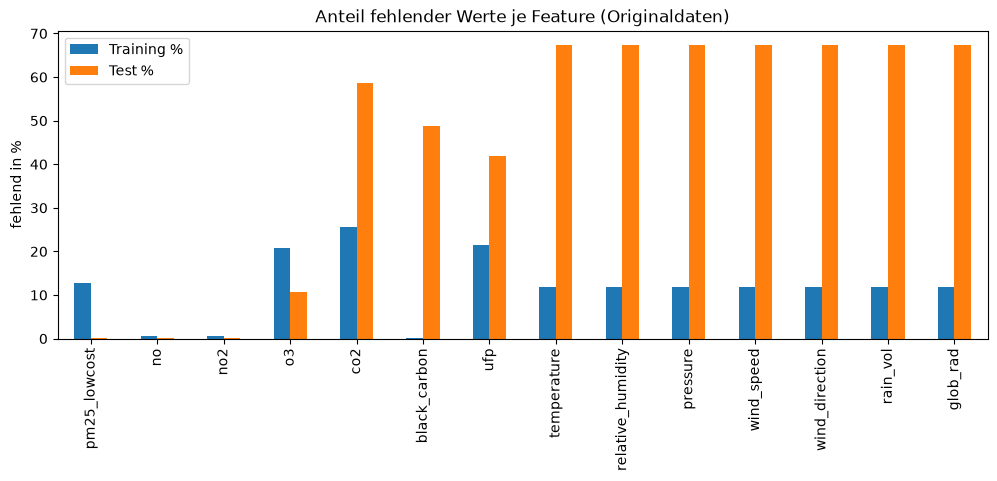

In [13]:
features_now = feature_columns(train_cur)
missing_share = pd.DataFrame({
    "Training %": df[features_now].isnull().sum() / len(df) * 100,
    "Test %": test[features_now].isnull().sum() / len(test) * 100}).round(1)
print(missing_share)
missing_share.plot.bar(figsize=(12, 4), title="Anteil fehlender Werte je Feature (Originaldaten)")
plt.ylabel("fehlend in %")
plt.show()

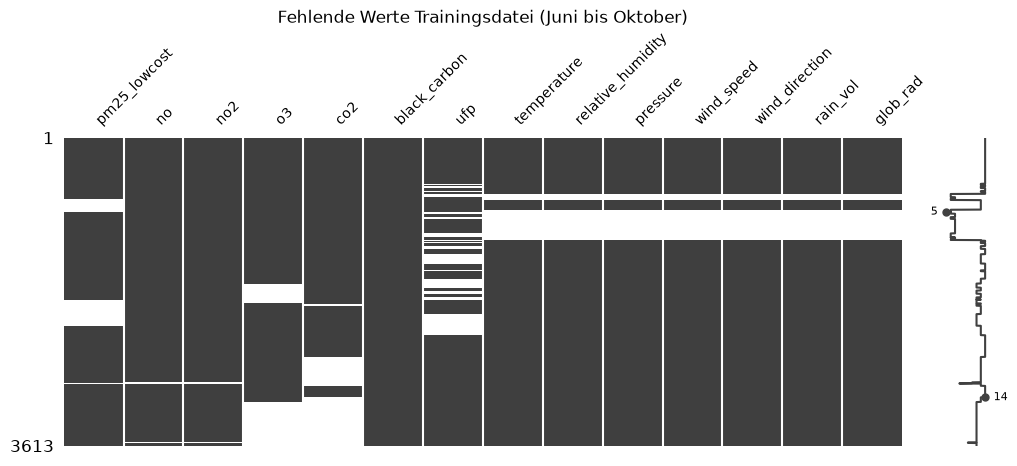

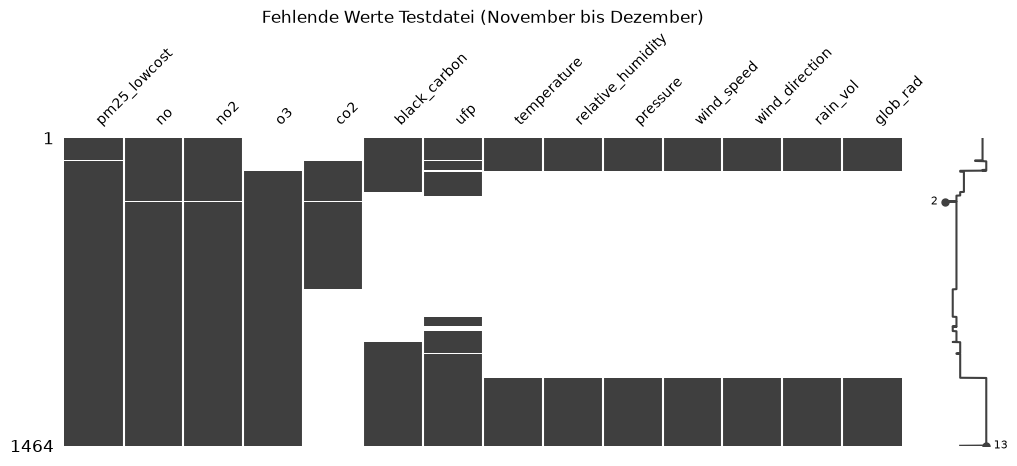

In [14]:
# Muster der fehlenden Werte über die Zeit (Zeilen sind chronologisch sortiert)
msno.matrix(df[features_now], figsize=(12, 4), fontsize=10)
plt.title("Fehlende Werte Trainingsdatei (Juni bis Oktober)")
plt.show()
msno.matrix(test[features_now], figsize=(12, 4), fontsize=10)
plt.title("Fehlende Werte Testdatei (November bis Dezember)")
plt.show()

**Beobachtung:**
- Die Testdaten haben ein ganz anderes Lückenmuster als die Trainingsdaten. Wetterdaten fehlen in 67 % der Testzeilen (Training 12 %), `co2` in 59 % (der gesamte Dezember), `black_carbon` in 49 % (Training 0,1 %) und `ufp` in 42 %. `pm25_lowcost` ist im Test dagegen fast vollständig.
- Die Matrix-Diagramme zeigen, dass die Werte **blockweise** fehlen: Ganze Sensoren fallen über Tage oder Wochen aus (z. B. die Wetterstation im Juli, `co2` ab Ende August). Das sind keine zufälligen Einzellücken.
- Konsequenz: In einem Großteil der Testzeilen müssen wichtige Features ersetzt werden, und zwar mit Werten aus den Sommer- und Herbstmonaten. Das ist ein Risiko für die Testleistung, das wir in Abschnitt 10 untersuchen.

**Varianten** (alle Ersatzwerte werden **nur aus den Trainingsdaten** berechnet):

| Variante | Methode | Vorlage im Kurs |
|---|---|---|
| 4a | Median der Trainingsdaten (robust gegenüber schiefen Verteilungen) | `fillna(median)`, Pipeline-Notebooks |
| 4b | Mittelwert der Trainingsdaten | `fillna(mean)`, Missing Value Handling |
| 4c | Regressions-Imputation für `pm25_lowcost` aus korrelierten, fast vollständigen Features; Rest Median | Missing Value Handling (Regression Imputation) |
| 4d | nur Training: Zeilen mit mehr als 3 fehlenden Features entfernen (Listwise Deletion); Rest Median | Missing Value Handling (Listwise Deletion) |

In [15]:
def impute(train_df, val_df, test_df, strategy):
    """Ersetzt fehlende Feature-Werte durch Median oder Mittelwert der Trainingsdaten."""
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    features = feature_columns(train_df)
    if strategy == "median":
        fill_values = train_df[features].median()
    else:
        fill_values = train_df[features].mean()
    for data in [train_df, val_df, test_df]:
        data[features] = data[features].fillna(fill_values)
    return train_df, val_df, test_df


def regression_impute(train_df, val_df, test_df, target_col, predictors):
    """Regressions-Imputation (Kurs-Muster): Regression auf den vollständigen Trainingszeilen lernen
    und damit die fehlenden Werte von target_col in allen drei Datensätzen vorhersagen."""
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    predictor_median = train_df[predictors].median()      # falls ein Prädiktor selbst fehlt
    ids = train_df[train_df[target_col].notnull()].index.values
    reg = linear_model.LinearRegression()
    reg.fit(train_df.loc[ids, predictors].fillna(predictor_median), train_df.loc[ids, target_col])
    for data in [train_df, val_df, test_df]:
        missing = data[target_col].isnull()
        if missing.sum() > 0:
            data.loc[missing, target_col] = reg.predict(data.loc[missing, predictors].fillna(predictor_median))
    return impute(train_df, val_df, test_df, "median")     # alle übrigen Lücken: Median


def drop_incomplete_train_rows(train_df, max_missing):
    """Listwise Deletion nur im Training: Zeilen mit mehr als max_missing fehlenden Features entfernen."""
    n_missing = train_df[feature_columns(train_df)].isnull().sum(axis=1)
    print(f"Listwise Deletion: {(n_missing > max_missing).sum()} Trainingszeilen mit mehr als {max_missing} fehlenden Features entfernt")
    return train_df[n_missing <= max_missing].copy()


# Welche fast vollständigen Features eignen sich als Prädiktoren für pm25_lowcost?
PREDICTORS_LOWCOST = ["no", "no2", "black_carbon"]
print("Korrelation mit pm25_lowcost (Training):")
print(train_cur[PREDICTORS_LOWCOST].corrwith(train_cur["pm25_lowcost"]).round(3))

Korrelation mit pm25_lowcost (Training):
no              0.243
no2             0.226
black_carbon    0.338
dtype: float64


In [16]:
variants = {}
rows_cum, rows_iso = [], []

# 4a Median
variants["4a"] = impute(train_cur, valid_cur, test_cur, "median")
rows_cum.append(evaluate("4a", "kumulativ", "Fehlwerte: Median der Trainingsdaten", variants["4a"][0], variants["4a"][1]))
# 4b Mittelwert
variants["4b"] = impute(train_cur, valid_cur, test_cur, "mean")
rows_cum.append(evaluate("4b", "kumulativ", "Fehlwerte: Mittelwert der Trainingsdaten", variants["4b"][0], variants["4b"][1]))
tr, va, te = impute(train, valid, test, "mean")
rows_iso.append(evaluate("4b", "isoliert", "Fehlwerte: Mittelwert der Trainingsdaten", tr, va))
# 4c Regressions-Imputation für pm25_lowcost
variants["4c"] = regression_impute(train_cur, valid_cur, test_cur, "pm25_lowcost", PREDICTORS_LOWCOST)
rows_cum.append(evaluate("4c", "kumulativ", "Fehlwerte: Regressions-Imputation pm25_lowcost (no, no2, black_carbon), Rest Median", variants["4c"][0], variants["4c"][1]))
tr, va, te = regression_impute(train, valid, test, "pm25_lowcost", PREDICTORS_LOWCOST)
rows_iso.append(evaluate("4c", "isoliert", "Fehlwerte: Regressions-Imputation pm25_lowcost (no, no2, black_carbon), Rest Median", tr, va))
# 4d Listwise Deletion (nur Training), danach Median
variants["4d"] = impute(drop_incomplete_train_rows(train_cur, 3), valid_cur, test_cur, "median")
rows_cum.append(evaluate("4d", "kumulativ", "Fehlwerte: nur Training Zeilen mit >3 fehlenden Features entfernt, Rest Median", variants["4d"][0], variants["4d"][1]))
tr, va, te = impute(drop_incomplete_train_rows(train, 3), valid, test, "median")
rows_iso.append(evaluate("4d", "isoliert", "Fehlwerte: nur Training Zeilen mit >3 fehlenden Features entfernt, Rest Median", tr, va))

for step_id in variants:
    check_integrity(variants[step_id][1], variants[step_id][2])
show(rows_cum + rows_iso)

Listwise Deletion: 318 Trainingszeilen mit mehr als 3 fehlenden Features entfernt
Listwise Deletion: 318 Trainingszeilen mit mehr als 3 fehlenden Features entfernt
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,4a,kumulativ,Fehlwerte: Median der Trainingsdaten,2727,14,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,91.0677
1,4b,kumulativ,Fehlwerte: Mittelwert der Trainingsdaten,2727,14,0.8679,0.8771,0.6803,0.6843,-0.4646,-34.6289,0.3253,90.5994
2,4c,kumulativ,Fehlwerte: Regressions-Imputation pm25_lowcost...,2727,14,0.8678,0.8824,0.6767,0.6768,-0.4593,-34.2348,0.3178,88.5028
3,4d,kumulativ,Fehlwerte: nur Training Zeilen mit >3 fehlende...,2409,14,0.8822,0.8926,0.6949,0.6813,-0.4491,-33.4721,0.3222,89.7497
4,4b,isoliert,Fehlwerte: Mittelwert der Trainingsdaten,2727,14,1.3290,1.3439,0.3153,0.3596,0.0022,0.1629,0.0005,0.1520
5,4c,isoliert,Fehlwerte: Regressions-Imputation pm25_lowcost...,2727,14,1.3266,1.3423,0.3181,0.3585,0.0006,0.0420,-0.0006,-0.1543
6,4d,isoliert,Fehlwerte: nur Training Zeilen mit >3 fehlende...,2409,14,1.3449,1.3582,0.3501,0.3761,0.0165,1.2320,0.0170,4.7410


Die Median-Imputation (4a) entspricht genau dem bisherigen Stand, weil `evaluate` verbleibende Lücken ohnehin mit dem Median füllt. Sie ist deshalb der Vergleichsmaßstab für die anderen Varianten. Nach diesem Schritt enthalten alle drei Datensätze keine fehlenden Feature-Werte mehr.

In [17]:
best = decide("Schritt 4 (fehlende Werte)", rows_cum[0], rows_cum[1:])
train_cur, valid_cur, test_cur = variants[best["Schritt"]]
if best is not rows_cum[0]:
    path.append(best)
current = best
check_integrity(valid_cur, test_cur)
print("Fehlende Feature-Werte nach Schritt 4:",
      "Training", train_cur[feature_columns(train_cur)].isnull().sum().sum(),
      "| Validierung", valid_cur[feature_columns(valid_cur)].isnull().sum().sum(),
      "| Test", test_cur[feature_columns(test_cur)].isnull().sum().sum())

ENTSCHEIDUNG Schritt 4 (fehlende Werte): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.8751, R2 Val 0.6860)
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Fehlende Feature-Werte nach Schritt 4: Training 0 | Validierung 0 | Test 0


**Interpretation:**
- **Der Median bleibt die beste Strategie** (MAE 0,875). Er ist robust gegenüber den schiefen Verteilungen. Der Mittelwert (4b) wird von hohen Werten nach oben gezogen und ist leicht schlechter.
- **Die Regressions-Imputation (4c) verschlechtert das Modell:** Die fast vollständigen Prädiktoren korrelieren nur schwach mit `pm25_lowcost` (r = 0,23 bis 0,34). Die vorhergesagten Ersatzwerte sind deshalb kaum besser als ein konstanter Wert, bringen aber zusätzliches Rauschen.
- **Listwise Deletion (4d) verschlechtert das Modell ebenfalls:** Es fallen 318 Trainingszeilen (12 %) weg, überwiegend aus dem Ausfallblock der Wetterstation im Juli. Das Modell verliert damit Trainingsbeispiele aus einem ganzen Zeitraum.
- Isoliert betrachtet sind alle Varianten nahezu wirkungslos (Veränderung des MAE unter 1,3 %). Die fehlenden Werte waren also nicht das Hauptproblem der Baseline, sondern die Ausreißer.
- Nach Schritt 4 enthalten Training, Validierung und Test keine fehlenden Feature-Werte mehr.

## 5 Feature-Transformation einzelner Merkmale

In diesem Abschnitt geht es um Features, deren **Darstellung** nicht zu einer linearen Regression passt. Die Befunde sind neu aus Aufgabe 2 bzw. aus Domänenwissen begründet:

| Variante | Problem | Transformation | Vorlage im Kurs |
|---|---|---|---|
| 5a | `rain_vol` ist ein **kumulativer Zähler** (siehe Diagramm unten): Er steigt über Monate, wird zurückgesetzt und hängt im November bei einem konstanten Wert. Für die Luftqualität ist aber der aktuelle Regen relevant. | Regenmenge pro Stunde als Differenz zur Vorstunde (`shift(1)`), Zähler-Resets auf 0 | `shift`, `clip` (Time-Series-Skripte) |
| 5b | wie 5a | `rain_vol` als Feature entfernen | `drop` |
| 5c | `wind_direction` ist ein **Winkel**: 359° und 1° liegen nebeneinander, als Zahl aber maximal weit auseinander | zyklische Kodierung mit Sinus und Kosinus | Transformation-Skript (zyklische Kodierung) |
| 5d | Low-Cost-Sensoren messen bei **hoher Luftfeuchte** zu hoch, weil Partikel Wasser aufnehmen (Abschnitt 3) | Interaktions-Feature `pm25_lowcost × relative_humidity` | neue Spalte aus Spalten berechnen (Pandas-Skript) |

5a und 5b sind Alternativen. 5c und 5d werden nacheinander jeweils auf dem besten Stand geprüft.

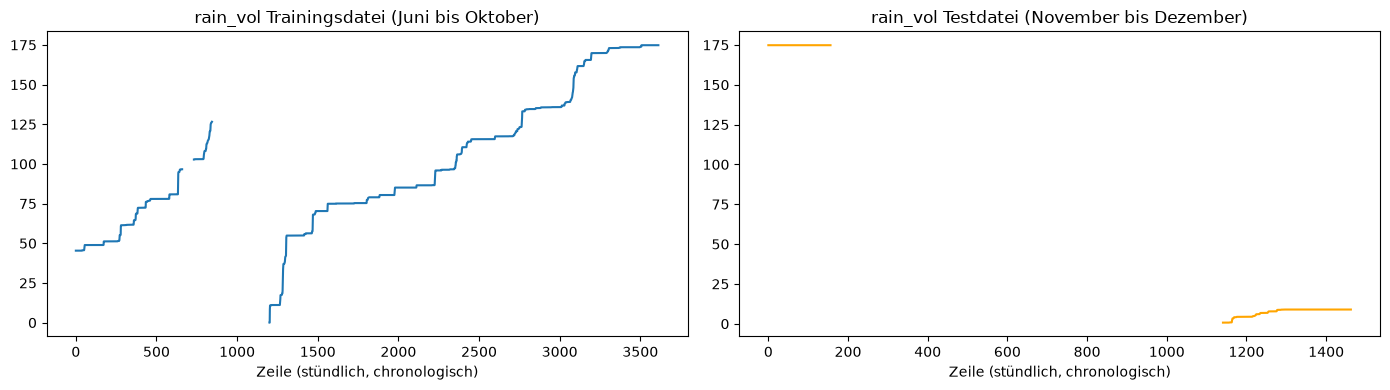

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot(df.index, df["rain_vol"])
axs[0].set_title("rain_vol Trainingsdatei (Juni bis Oktober)")
axs[0].set_xlabel("Zeile (stündlich, chronologisch)")
axs[1].plot(test.index, test["rain_vol"], color="orange")
axs[1].set_title("rain_vol Testdatei (November bis Dezember)")
axs[1].set_xlabel("Zeile (stündlich, chronologisch)")
plt.tight_layout()
plt.show()

In [19]:
# Regen pro Stunde wird auf den chronologisch sortierten Originaldateien berechnet,
# weil der Split die Zeilen mischt. Über den Index wird er danach den Datensätzen zugeordnet.
RAIN_PER_HOUR_TRAINFILE = (df["rain_vol"] - df["rain_vol"].shift(1)).clip(lower=0)
RAIN_PER_HOUR_TESTFILE = (test["rain_vol"] - test["rain_vol"].shift(1)).clip(lower=0)


def rain_per_hour(train_df, val_df, test_df):
    """5a: ersetzt den kumulativen Zähler rain_vol durch die Regenmenge pro Stunde (rain_1h)."""
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    train_df["rain_vol"] = RAIN_PER_HOUR_TRAINFILE.loc[train_df.index]
    val_df["rain_vol"] = RAIN_PER_HOUR_TRAINFILE.loc[val_df.index]
    test_df["rain_vol"] = RAIN_PER_HOUR_TESTFILE.loc[test_df.index]
    fill_value = train_df["rain_vol"].median()            # Lücken (z. B. nach Ausfällen): Trainings-Median
    result = []
    for data in [train_df, val_df, test_df]:
        data["rain_vol"] = data["rain_vol"].fillna(fill_value)
        result.append(data.rename(columns={"rain_vol": "rain_1h"}))
    return result[0], result[1], result[2]


def drop_features(train_df, val_df, test_df, columns):
    """Entfernt Feature-Spalten aus allen drei Datensätzen."""
    return train_df.drop(columns=columns), val_df.drop(columns=columns), test_df.drop(columns=columns)


def wind_cyclic(train_df, val_df, test_df):
    """5c: zyklische Kodierung der Windrichtung (Grad) mit Sinus und Kosinus."""
    result = []
    for data in [train_df, val_df, test_df]:
        data = data.copy()
        data["wind_sin"] = np.sin(2 * np.pi * data["wind_direction"] / 360)
        data["wind_cos"] = np.cos(2 * np.pi * data["wind_direction"] / 360)
        result.append(data.drop(columns=["wind_direction"]))
    return result[0], result[1], result[2]


def add_humidity_interaction(train_df, val_df, test_df):
    """5d: Interaktion zwischen Low-Cost-Messwert und Luftfeuchte."""
    result = []
    for data in [train_df, val_df, test_df]:
        data = data.copy()
        data["lowcost_x_humidity"] = data["pm25_lowcost"] * data["relative_humidity"]
        result.append(data)
    return result[0], result[1], result[2]

In [20]:
# 5a / 5b: Alternativen für rain_vol
variants = {"5a": rain_per_hour(train_cur, valid_cur, test_cur),
            "5b": drop_features(train_cur, valid_cur, test_cur, ["rain_vol"])}
r5a = evaluate("5a", "kumulativ", "rain_vol (Zähler) -> Regen pro Stunde rain_1h", variants["5a"][0], variants["5a"][1])
r5b = evaluate("5b", "kumulativ", "rain_vol entfernt", variants["5b"][0], variants["5b"][1])
tr, va, te = rain_per_hour(train, valid, test)
r5a_iso = evaluate("5a", "isoliert", "rain_vol (Zähler) -> Regen pro Stunde rain_1h", tr, va)
tr, va, te = drop_features(train, valid, test, ["rain_vol"])
r5b_iso = evaluate("5b", "isoliert", "rain_vol entfernt", tr, va)
show([current, r5a, r5b, r5a_iso, r5b_iso])

,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,4a,kumulativ,Fehlwerte: Median der Trainingsdaten,2727,14,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,91.0677
1,5a,kumulativ,rain_vol (Zähler) -> Regen pro Stunde rain_1h,2727,14,0.8609,0.8742,0.6831,0.6825,-0.4675,-34.8460,0.3234,90.0748
2,5b,kumulativ,rain_vol entfernt,2727,13,0.8646,0.8761,0.6827,0.6818,-0.4656,-34.7000,0.3227,89.8809
3,5a,isoliert,rain_vol (Zähler) -> Regen pro Stunde rain_1h,2727,14,1.3267,1.3425,0.3182,0.3591,0.0008,0.0588,0.0000,0.0056
4,5b,isoliert,rain_vol entfernt,2727,13,1.3265,1.3425,0.3182,0.3593,0.0008,0.0561,0.0002,0.0631


In [21]:
best = decide("Schritt 5a/5b (rain_vol)", current, [r5a, r5b])
if best is not current:
    train_cur, valid_cur, test_cur = variants[best["Schritt"]]
    current = best
    path.append(best)
check_integrity(valid_cur, test_cur)

ENTSCHEIDUNG Schritt 5a/5b (rain_vol): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.8751, R2 Val 0.6860)
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


In [22]:
# 5c: Windrichtung zyklisch kodieren
tr5c, va5c, te5c = wind_cyclic(train_cur, valid_cur, test_cur)
r5c = evaluate("5c", "kumulativ", "wind_direction -> wind_sin, wind_cos", tr5c, va5c)
tr, va, te = wind_cyclic(train, valid, test)
r5c_iso = evaluate("5c", "isoliert", "wind_direction -> wind_sin, wind_cos", tr, va)
best = decide("Schritt 5c (Windrichtung)", current, [r5c])
if best is not current:
    train_cur, valid_cur, test_cur = tr5c, va5c, te5c
    current = best
    path.append(best)

# 5d: Interaktion Low-Cost-Sensor x Luftfeuchte
tr5d, va5d, te5d = add_humidity_interaction(train_cur, valid_cur, test_cur)
r5d = evaluate("5d", "kumulativ", "neues Feature lowcost_x_humidity = pm25_lowcost * relative_humidity", tr5d, va5d)
tr, va, te = add_humidity_interaction(train, valid, test)
r5d_iso = evaluate("5d", "isoliert", "neues Feature lowcost_x_humidity = pm25_lowcost * relative_humidity", tr, va)
best = decide("Schritt 5d (Interaktion)", current, [r5d])
if best is not current:
    train_cur, valid_cur, test_cur = tr5d, va5d, te5d
    current = best
    path.append(best)
check_integrity(valid_cur, test_cur)
show([r5c, r5c_iso, r5d, r5d_iso])

ENTSCHEIDUNG Schritt 5c (Windrichtung): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.8751, R2 Val 0.6860)
ENTSCHEIDUNG Schritt 5d (Interaktion): übernommen wird 5d 'neues Feature lowcost_x_humidity = pm25_lowcost * relative_humidity' (MAE Val 0.8751 -> 0.7657, R2 Val 0.6860 -> 0.7852)
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,5c,kumulativ,"wind_direction -> wind_sin, wind_cos",2727,15,0.8654,0.8771,0.6887,0.6936,-0.4646,-34.6311,0.3345,93.1681
1,5c,isoliert,"wind_direction -> wind_sin, wind_cos",2727,15,1.3260,1.3152,0.3241,0.3806,-0.0265,-1.9765,0.0216,6.0031
2,5d,kumulativ,neues Feature lowcost_x_humidity = pm25_lowcos...,2727,15,0.7605,0.7657,0.7667,0.7852,-0.5760,-42.9300,0.4262,118.6959
3,5d,isoliert,neues Feature lowcost_x_humidity = pm25_lowcos...,2727,15,1.1399,1.1605,0.4642,0.5058,-0.1812,-13.5055,0.1468,40.8846


**Interpretation:**
- **`rain_vol` (5a/5b):** Die Diagramme bestätigen, dass `rain_vol` ein kumulativer Zähler ist. Er steigt im Training von 45 auf 175, springt im Juli auf 0 zurück und steht im Test den ganzen November auf 174,82. Die Umrechnung in Regen pro Stunde (5a) senkt den MAE minimal (0,8742), verschlechtert aber R² (0,6825). Das Entfernen (5b) ist leicht schlechter. Nach unserer Regel wird keine Variante übernommen: Regen hat in diesen Daten keinen messbaren linearen Einfluss auf das Label. Fachlich bleibt der Zähler problematisch, weil seine Werte im Test nicht mit dem Training vergleichbar sind. Wir prüfen ihn in Abschnitt 8 noch einmal.
- **Windrichtung (5c):** Die zyklische Kodierung verbessert R² leicht (0,6936), der MAE wird aber schlechter (0,8771). Die Regel verlangt beides, deshalb wird 5c nicht übernommen. Die Hälfte der Messungen liegt zwischen 107° und 213° (Ost-Südost bis Südwest), also weit weg vom Übergang 359° → 0°, an dem die zyklische Kodierung ihren Vorteil hätte.
- **Die Interaktion Low-Cost × Luftfeuchte (5d) ist der zweitgrößte Hebel:** Der MAE sinkt von 0,875 auf 0,766, R² steigt von 0,686 auf 0,785. Auch isoliert auf den Originaldaten verbessert das Feature den MAE um 13,5 %. Damit bestätigt sich die Beobachtung aus Abschnitt 3: Wie stark man dem Low-Cost-Sensor trauen kann, hängt von der Luftfeuchte ab. Ein rein additives lineares Modell kann das nicht abbilden, das Produkt beider Features schon (Koeffizienten siehe Abschnitt 7).

## 6 Verteilungs-Transformation

**Begründung (Aufgabe 1):** Die Histogramme zeigten stark rechtsschiefe Verteilungen. Bei einer linearen Regression führt das dazu, dass wenige große Werte die Steigung bestimmen und der Zusammenhang im Bereich der typischen Werte schlecht abgebildet wird. Nach der Ausreißerbehandlung prüfen wir die Schiefe (`skew`) erneut und transformieren nur Features mit |Schiefe| > 1.

**Varianten** (Transformer werden **nur auf den Trainingsdaten** gelernt):

| Variante | Methode | Vorlage im Kurs |
|---|---|---|
| 6a | `PowerTransformer` (Yeo-Johnson), macht die Verteilung möglichst normalverteilt | Transformation-Skript |
| 6b | `QuantileTransformer` mit Normalverteilung als Ziel | Transformation-Skript |
| 6c | wie 6a, aber ohne `pm25_lowcost` und Interaktions-Feature (Begründung folgt nach 6a/6b) | Transformation-Skript |

Schiefe der Features (Training, aktueller Stand):
no                    1.96
glob_rad              1.76
lowcost_x_humidity    1.67
pm25_lowcost          1.51
wind_speed            1.46
black_carbon          1.18
co2                   0.98
no2                   0.62
ufp                   0.62
o3                    0.55
temperature           0.33
rain_vol              0.30
pressure             -0.33
wind_direction       -0.72
relative_humidity    -0.86
dtype: float64

Zu transformierende Features (|Schiefe| > 1): ['pm25_lowcost', 'no', 'black_carbon', 'wind_speed', 'glob_rad', 'lowcost_x_humidity']

Histogramme VOR der Transformation (Training):


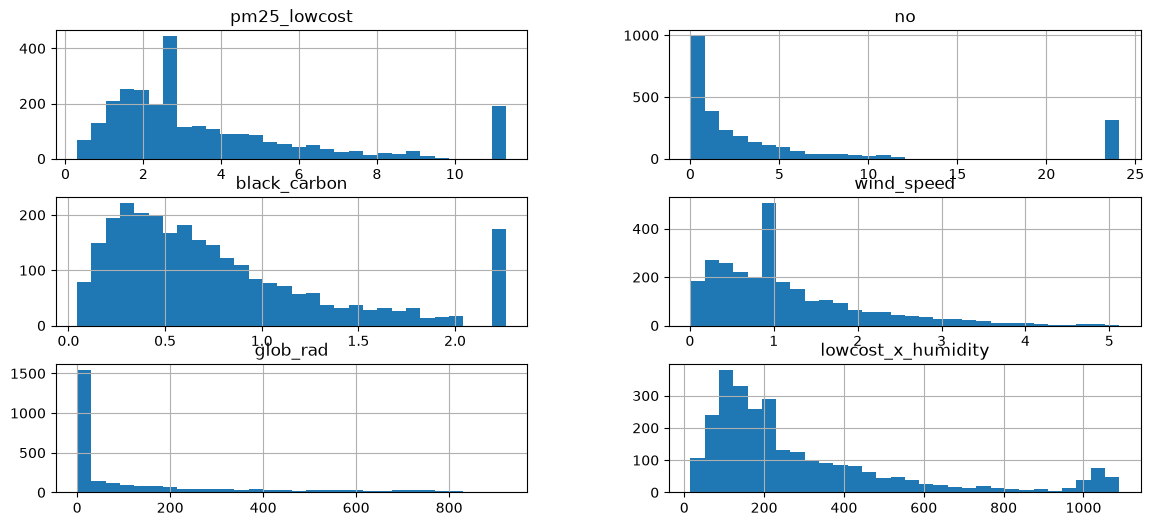

In [23]:
skew_before = train_cur[feature_columns(train_cur)].skew()
SKEW_COLS = list(skew_before[skew_before.abs() > 1].index)
print("Schiefe der Features (Training, aktueller Stand):")
print(skew_before.round(2).sort_values(ascending=False))
print("\nZu transformierende Features (|Schiefe| > 1):", SKEW_COLS)
print("\nHistogramme VOR der Transformation (Training):")
train_cur[SKEW_COLS].hist(bins=30, figsize=(14, 6))
plt.show()

In [24]:
def transform_distribution(train_df, val_df, test_df, columns, method):
    """Verteilungs-Transformation: Transformer nur auf Training lernen, auf alle drei Datensätze anwenden."""
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    if method == "power":
        transformer = PowerTransformer()                     # Yeo-Johnson
    else:
        transformer = QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=0)
    transformer.fit(train_df[columns])
    for data in [train_df, val_df, test_df]:
        data[columns] = transformer.transform(data[columns])
    return train_df, val_df, test_df


variants = {"6a": transform_distribution(train_cur, valid_cur, test_cur, SKEW_COLS, "power"),
            "6b": transform_distribution(train_cur, valid_cur, test_cur, SKEW_COLS, "quantile")}
r6a = evaluate("6a", "kumulativ", "PowerTransformer (Yeo-Johnson) auf " + str(SKEW_COLS), variants["6a"][0], variants["6a"][1])
r6b = evaluate("6b", "kumulativ", "QuantileTransformer (normal) auf " + str(SKEW_COLS), variants["6b"][0], variants["6b"][1])
# isoliert: nur die Transformation auf den Originaldaten (nur Spalten, die dort existieren)
iso_cols = [col for col in SKEW_COLS if col in train.columns]
tr, va, te = transform_distribution(train, valid, test, iso_cols, "power")
r6a_iso = evaluate("6a", "isoliert", "PowerTransformer (Yeo-Johnson) auf " + str(iso_cols), tr, va)
tr, va, te = transform_distribution(train, valid, test, iso_cols, "quantile")
r6b_iso = evaluate("6b", "isoliert", "QuantileTransformer (normal) auf " + str(iso_cols), tr, va)
check_integrity(variants["6a"][1], variants["6a"][2])
show([current, r6a, r6b, r6a_iso, r6b_iso])

Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,5d,kumulativ,neues Feature lowcost_x_humidity = pm25_lowcos...,2727,15,0.7605,0.7657,0.7667,0.7852,-0.5760,-42.9300,0.4262,118.6959
1,6a,kumulativ,PowerTransformer (Yeo-Johnson) auf ['pm25_lowc...,2727,15,0.8322,0.8579,0.7097,0.7033,-0.4838,-36.0579,0.3442,95.8778
2,6b,kumulativ,QuantileTransformer (normal) auf ['pm25_lowcos...,2727,15,0.9098,0.9152,0.6428,0.6617,-0.4265,-31.7907,0.3027,84.3029
3,6a,isoliert,PowerTransformer (Yeo-Johnson) auf ['pm25_lowc...,2727,14,0.8689,0.8966,0.6771,0.6692,-0.4451,-33.1730,0.3102,86.3897
4,6b,isoliert,QuantileTransformer (normal) auf ['pm25_lowcos...,2727,14,0.8806,0.9107,0.6614,0.6597,-0.4310,-32.1257,0.3006,83.7312


ENTSCHEIDUNG Schritt 6a/6b (Verteilungs-Transformation): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.7657, R2 Val 0.7852)
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
                    Schiefe vorher  Schiefe nach 6a
pm25_lowcost                  1.51             0.03
no                            1.96             0.16
black_carbon                  1.18             0.09
wind_speed                    1.46             0.04
glob_rad                      1.76            -0.00
lowcost_x_humidity            1.67             0.00

Histogramme NACH dem PowerTransformer (Variante 6a, Training):


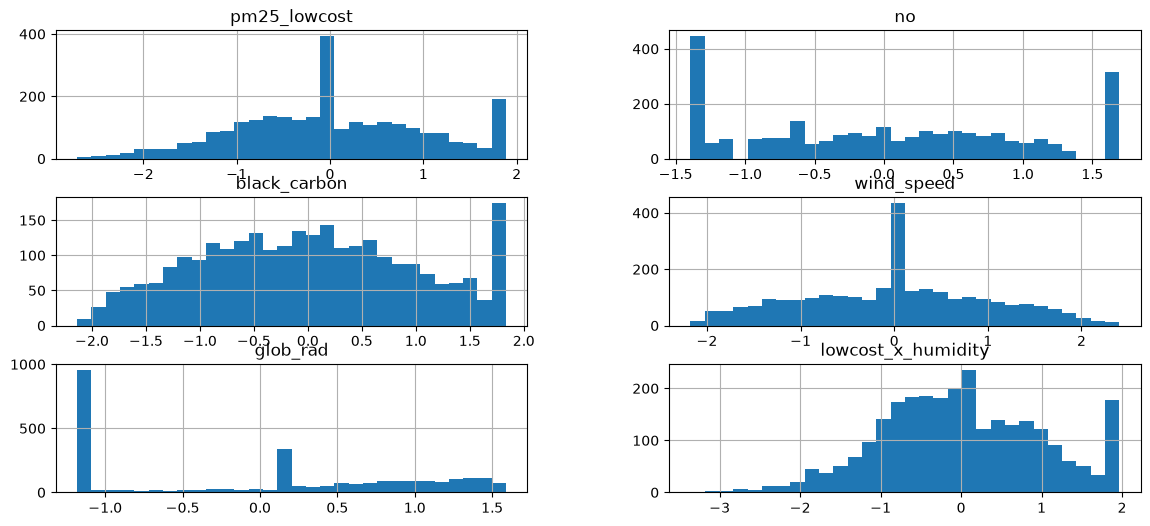

In [25]:
best = decide("Schritt 6a/6b (Verteilungs-Transformation)", current, [r6a, r6b])
if best is not current:
    train_cur, valid_cur, test_cur = variants[best["Schritt"]]
    current = best
    path.append(best)
check_integrity(valid_cur, test_cur)

# Wirkung des PowerTransformers auf die Verteilungen (Variante 6a, unabhängig von der Entscheidung)
skew_6a = variants["6a"][0][SKEW_COLS].skew()
print(pd.DataFrame({"Schiefe vorher": skew_before[SKEW_COLS], "Schiefe nach 6a": skew_6a}).round(2))
print("\nHistogramme NACH dem PowerTransformer (Variante 6a, Training):")
variants["6a"][0][SKEW_COLS].hist(bins=30, figsize=(14, 6))
plt.show()

**Neue Erkenntnis aus 6a/6b:** Statistisch erfüllt der PowerTransformer seine Aufgabe: Die Schiefe aller transformierten Features sinkt auf etwa 0. Das Modell wird aber deutlich **schlechter** (MAE 0,858 bzw. 0,915 statt 0,766). Aufschlussreich ist der Vergleich mit der isolierten Bewertung: Auf den Originaldaten verbessert 6a den MAE um 33 %, weil die log-ähnliche Transformation dort vor allem die Ausreißer dämpft. Diese Aufgabe übernimmt nach Schritt 3 aber bereits das Kappen.

**Variante 6c – Transformation ohne den Low-Cost-Sensor:** `pm25_lowcost` und das Label messen dieselbe physikalische Größe. Nach der Ausreißerbehandlung hängen sie deshalb annähernd linear zusammen (siehe Verhältnis unten). Eine log-ähnliche Transformation würde diesen linearen Zusammenhang krümmen, genauso beim Interaktions-Feature. In 6c transformieren wir deshalb nur die übrigen schiefen Features.

In [26]:
print(f"Median des Verhältnisses pm25_lowcost / pm25_target (Training, Originaldaten): "
      f"{(train['pm25_lowcost'] / train[LABEL]).median():.2f}")

SKEW_COLS_6C = [col for col in SKEW_COLS if col not in ["pm25_lowcost", "lowcost_x_humidity"]]
variants["6c"] = transform_distribution(train_cur, valid_cur, test_cur, SKEW_COLS_6C, "power")
r6c = evaluate("6c", "kumulativ", "PowerTransformer (Yeo-Johnson) nur auf " + str(SKEW_COLS_6C), variants["6c"][0], variants["6c"][1])
iso_cols = [col for col in SKEW_COLS_6C if col in train.columns]
tr, va, te = transform_distribution(train, valid, test, iso_cols, "power")
r6c_iso = evaluate("6c", "isoliert", "PowerTransformer (Yeo-Johnson) nur auf " + str(iso_cols), tr, va)
check_integrity(variants["6c"][1], variants["6c"][2])
show([current, r6c, r6c_iso])

Median des Verhältnisses pm25_lowcost / pm25_target (Training, Originaldaten): 1.03


Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,5d,kumulativ,neues Feature lowcost_x_humidity = pm25_lowcos...,2727,15,0.7605,0.7657,0.7667,0.7852,-0.5760,-42.9300,0.4262,118.6959
1,6c,kumulativ,"PowerTransformer (Yeo-Johnson) nur auf ['no', ...",2727,15,0.7590,0.7868,0.7696,0.7764,-0.5549,-41.3555,0.4174,116.2520
2,6c,isoliert,"PowerTransformer (Yeo-Johnson) nur auf ['no', ...",2727,14,1.2277,1.2329,0.4078,0.4405,-0.1088,-8.1086,0.0815,22.6894


In [27]:
best = decide("Schritt 6c (Transformation ohne Low-Cost-Sensor)", current, [r6c])
if best is not current:
    train_cur, valid_cur, test_cur = variants["6c"]
    current = best
    path.append(best)
check_integrity(valid_cur, test_cur)

ENTSCHEIDUNG Schritt 6c (Transformation ohne Low-Cost-Sensor): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.7657, R2 Val 0.7852)
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


**Interpretation:**
- Auch ohne `pm25_lowcost` und Interaktion (6c) verschlechtert die Transformation das Modell (MAE 0,787 statt 0,766). Es wird keine Verteilungs-Transformation übernommen.
- Der Median des Verhältnisses Low-Cost/Referenz liegt bei 1,03: Im Normalfall messen beide Geräte fast dasselbe. Diesen linearen 1:1-Zusammenhang kann eine lineare Regression gut abbilden, eine Transformation, die die Features krümmt, schadet ihm.
- **Learning:** Normalverteilte Features sind keine Voraussetzung der linearen Regression (die Annahme betrifft die Fehlerterme). Eine Transformation hilft nur, wenn sie den Zusammenhang zum Label linearer macht. Nach dem Kappen der Ausreißer und mit der Interaktion ist er bereits linear genug.
- Ausreißerbehandlung und Transformation lösen teilweise dasselbe Problem (Extremwerte), deshalb addieren sich ihre Effekte nicht. Das zeigt, warum wir jeden Schritt sowohl isoliert als auch kumulativ bewerten.

## 7 Skalierung

**Begründung (Aufgabe 1):** Die Features haben sehr unterschiedliche Wertebereiche (z. B. `black_carbon` um 1, `ufp` um 10.000). Wir vergleichen die drei Scaler aus dem Kurs, jeweils nur auf den Trainingsdaten gelernt:

| Variante | Scaler | Formel |
|---|---|---|
| 7a | `StandardScaler` | (x − Mittelwert) / Standardabweichung |
| 7b | `MinMaxScaler` | (x − min) / (max − min) |
| 7c | `RobustScaler` | (x − Median) / IQR |

**Erwartung:** Eine lineare Regression gleicht unterschiedliche Skalen über ihre Koeffizienten selbst aus. Skalierung sollte MAE und R² daher **nicht** verändern. Der Schritt ist trotzdem wichtig: Die Koeffizienten werden vergleichbar (Feature Importance), und in Aufgabe 3 brauchen distanzbasierte Verfahren wie KNN skalierte Daten.

In [28]:
def scale(train_df, val_df, test_df, scaler):
    """Skalierung aller Features: Scaler nur auf Training lernen, auf alle drei Datensätze anwenden."""
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    features = feature_columns(train_df)
    scaler.fit(train_df[features])
    for data in [train_df, val_df, test_df]:
        data[features] = scaler.transform(data[features])
    return train_df, val_df, test_df


variants = {"7a": scale(train_cur, valid_cur, test_cur, StandardScaler()),
            "7b": scale(train_cur, valid_cur, test_cur, MinMaxScaler()),
            "7c": scale(train_cur, valid_cur, test_cur, RobustScaler())}
r7a = evaluate("7a", "kumulativ", "StandardScaler auf allen Features", variants["7a"][0], variants["7a"][1])
r7b = evaluate("7b", "kumulativ", "MinMaxScaler auf allen Features", variants["7b"][0], variants["7b"][1])
r7c = evaluate("7c", "kumulativ", "RobustScaler auf allen Features", variants["7c"][0], variants["7c"][1])
show([current, r7a, r7b, r7c])

,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,5d,kumulativ,neues Feature lowcost_x_humidity = pm25_lowcos...,2727,15,0.7605,0.7657,0.7667,0.7852,-0.576,-42.93,0.4262,118.6959
1,7a,kumulativ,StandardScaler auf allen Features,2727,15,0.7605,0.7657,0.7667,0.7852,-0.576,-42.93,0.4262,118.6959
2,7b,kumulativ,MinMaxScaler auf allen Features,2727,15,0.7605,0.7657,0.7667,0.7852,-0.576,-42.93,0.4262,118.6959
3,7c,kumulativ,RobustScaler auf allen Features,2727,15,0.7605,0.7657,0.7667,0.7852,-0.576,-42.93,0.4262,118.6959


Die Ergebnisse bestätigen die Erwartung: Alle drei Scaler liefern (bis auf Rundungsfehler) dieselben Kennzahlen wie der unskalierte Stand. Nach unserer Entscheidungsregel würde keine Variante übernommen, weil sich der MAE nicht verbessert. Hier machen wir **bewusst eine begründete Ausnahme** und übernehmen den `StandardScaler`:
- Die Koeffizienten der Regression werden vergleichbar und zeigen die Wichtigkeit der Features (siehe Diagramm).
- Aufgabe 3 baut auf den exportierten Daten auf, und Verfahren wie KNN oder polynomiale Regression brauchen skalierte Daten.
- Nach der Ausreißerbehandlung gibt es keine Extremwerte mehr, die Mittelwert und Standardabweichung verzerren. Der `StandardScaler`, der auch in den Kurs-Pipelines verwendet wird, ist deshalb gut geeignet.

Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Koeffizienten (standardisierte Features), sortiert:
lowcost_x_humidity   -6.720
no                   -0.342
wind_direction       -0.279
rain_vol             -0.177
no2                  -0.132
ufp                  -0.071
wind_speed            0.001
pressure              0.161
co2                   0.199
o3                    0.303
glob_rad              0.388
temperature           0.569
black_carbon          1.071
relative_humidity     1.097
pm25_lowcost          7.601
dtype: float64


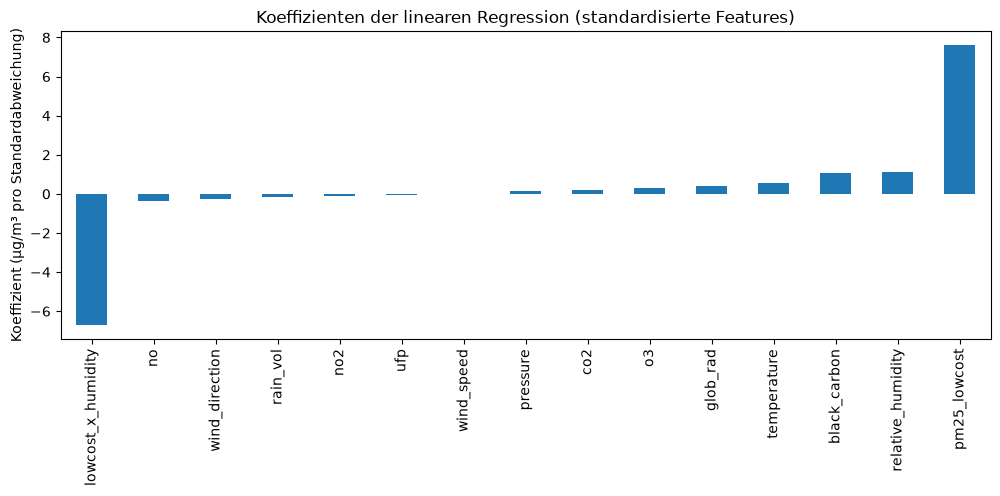

In [29]:
train_cur, valid_cur, test_cur = variants["7a"]
current = r7a
path.append(r7a)
check_integrity(valid_cur, test_cur)
with open(LOG_FILE, "a", encoding="utf-8") as log:
    log.write("ENTSCHEIDUNG Schritt 7 (Skalierung): 7a StandardScaler übernommen (begründete Ausnahme: "
              "MAE unverändert, aber vergleichbare Koeffizienten und Voraussetzung für Aufgabe 3)\n")

# Feature Importance: Koeffizienten der linearen Regression auf standardisierten Features
features = feature_columns(train_cur)
reg = linear_model.LinearRegression()
reg.fit(train_cur[features], train_cur[LABEL])
coefficients = pd.Series(reg.coef_, index=features).sort_values()
print("Koeffizienten (standardisierte Features), sortiert:")
print(coefficients.round(3))
coefficients.plot.bar(figsize=(12, 4), title="Koeffizienten der linearen Regression (standardisierte Features)")
plt.ylabel("Koeffizient (µg/m³ pro Standardabweichung)")
plt.show()

**Interpretation:**
- Wie erwartet ändert die Skalierung weder MAE noch R². Übernommen wird der StandardScaler (begründete Ausnahme, siehe oben).
- Die standardisierten Koeffizienten zeigen, welche Features das Modell am stärksten nutzt. Es dominieren `pm25_lowcost` (+7,6) und die Interaktion `lowcost_x_humidity` (−6,7). Die beiden müssen zusammen gelesen werden: Je höher die Luftfeuchte, desto stärker wird der Low-Cost-Wert nach unten korrigiert. Das ist genau die physikalisch erwartete Feuchte-Korrektur.
- Danach folgen `relative_humidity` (+1,1) und `black_carbon` (+1,1). Ruß stammt wie ein Teil des Feinstaubs aus Verbrennungsprozessen (Verkehr, Schiffsdiesel, Heizung) und ist deshalb ein guter zusätzlicher Indikator.
- Alle übrigen Features haben Koeffizienten unter 0,6 und spielen nur eine kleine Rolle.
- Weil `pm25_lowcost` und die Interaktion stark korrelieren, lassen sich ihre Koeffizienten nur gemeinsam interpretieren (siehe VIF in Abschnitt 8).

## 8 Feature Selection

**Begründung:** In Aufgabe 1 fielen starke Korrelationen zwischen Features auf (Multikollinearität), und in der schrittweisen Feature-Auswahl (1b) verschlechterte `no2` als letztes Feature das Modell. Mit den Methoden aus dem Kurs-Skript zur Feature Selection prüfen wir:
1. die Korrelation jedes Features mit dem Label (`corrwith`),
2. die Korrelationen der Features untereinander (Heatmap),
3. den Variance Inflation Factor (VIF) mit der Funktion `calc_vif` aus dem Kurs. Ein VIF über 5 gilt als Hinweis auf Multikollinearität.

Korrelation mit dem Label (Training, aktueller Stand):
wind_direction       -0.184
wind_speed           -0.161
rain_vol             -0.001
o3                    0.003
glob_rad              0.066
relative_humidity     0.102
temperature           0.117
co2                   0.205
ufp                   0.217
no                    0.228
pressure              0.237
no2                   0.288
black_carbon          0.499
lowcost_x_humidity    0.544
pm25_lowcost          0.606
dtype: float64


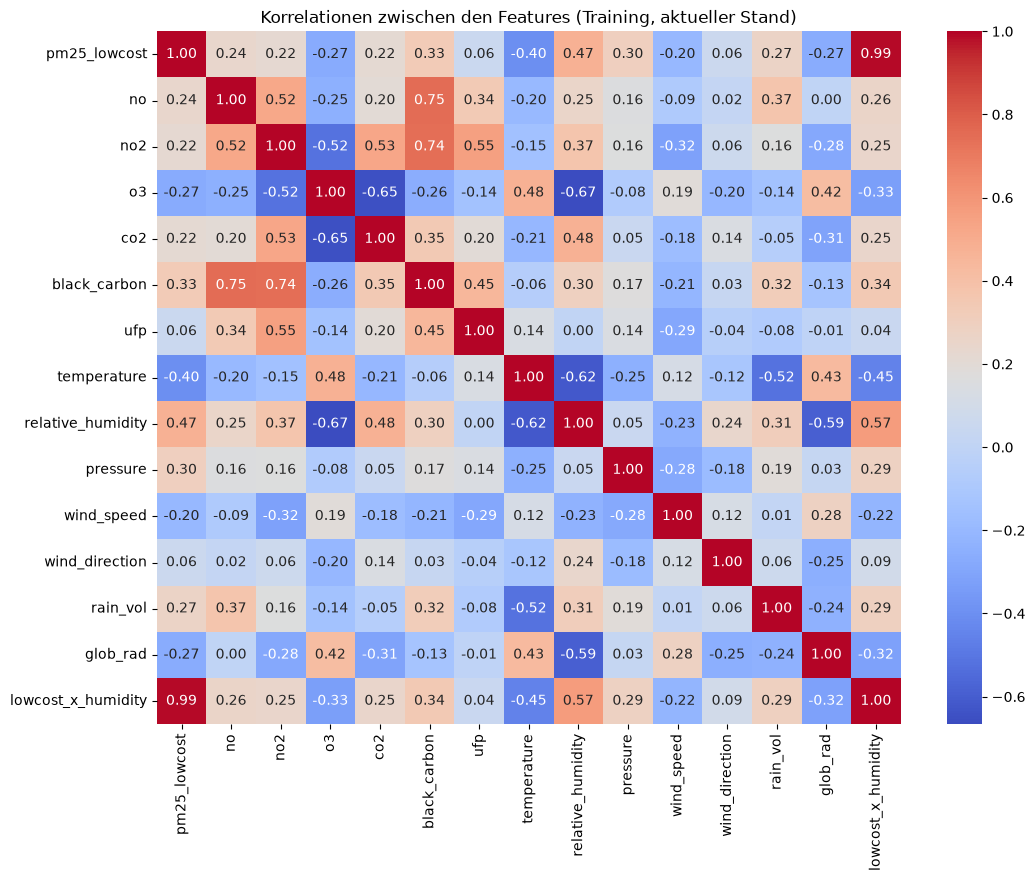

In [30]:
features = feature_columns(train_cur)
corr_with_label = train_cur[features].corrwith(train_cur[LABEL]).sort_values()
print("Korrelation mit dem Label (Training, aktueller Stand):")
print(corr_with_label.round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(train_cur[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korrelationen zwischen den Features (Training, aktueller Stand)")
plt.show()

In [31]:
def calc_vif(df):
    vif = pd.DataFrame()
    vif["features"] = df.columns
    vif["VIF Factor"] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
    return vif


vif_table = calc_vif(train_cur[features]).sort_values("VIF Factor", ascending=False)
vif_table.round(2)

,features,VIF Factor
14,lowcost_x_humidity,115.70
0,pm25_lowcost,100.06
8,relative_humidity,6.10
5,black_carbon,5.02
2,no2,3.95
3,o3,2.97
1,no,2.84
7,temperature,2.74
4,co2,2.16
13,glob_rad,1.92


**Kandidaten zum Entfernen** leiten wir aus den drei Analysen ab:
- Features mit sehr schwacher Korrelation zum Label (|r| < 0,05),
- das Feature mit dem höchsten VIF, falls dieser über 5 liegt,
- `no2`, weil es in Aufgabe 1b das Modell verschlechtert hat.

Jeder Kandidat wird einzeln auf dem aktuellen Stand geprüft. Er wird nur entfernt, wenn die Entscheidungsregel erfüllt ist.

In [32]:
candidates = list(corr_with_label[corr_with_label.abs() < 0.05].index)
top_vif = vif_table.iloc[0]
if top_vif["VIF Factor"] > 5 and top_vif["features"] not in candidates:
    candidates.append(top_vif["features"])
if "no2" not in candidates:
    candidates.append("no2")
print("Kandidaten zum Entfernen:", candidates)

rows_fs = []
for col in candidates:
    tr, va, te = drop_features(train_cur, valid_cur, test_cur, [col])
    row = evaluate("8 " + col, "kumulativ", "Feature Selection: " + col + " entfernt", tr, va)
    rows_fs.append(row)
    best = decide("Schritt 8 (" + col + " entfernen)", current, [row])
    if best is not current:
        train_cur, valid_cur, test_cur = tr, va, te
        current = best
        path.append(best)
check_integrity(valid_cur, test_cur)
show([current] + rows_fs)

Kandidaten zum Entfernen: ['rain_vol', 'o3', 'lowcost_x_humidity', 'no2']
ENTSCHEIDUNG Schritt 8 (rain_vol entfernen): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.7657, R2 Val 0.7852)
ENTSCHEIDUNG Schritt 8 (o3 entfernen): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.7657, R2 Val 0.7852)
ENTSCHEIDUNG Schritt 8 (lowcost_x_humidity entfernen): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.7657, R2 Val 0.7852)
ENTSCHEIDUNG Schritt 8 (no2 entfernen): keine Variante übernommen, bisheriger Stand bleibt (MAE Val 0.7657, R2 Val 0.7852)
Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,Schritt,Art,Beschreibung,Zeilen_Train,Features,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_rel_%,dR2_abs,dR2_rel_%
0,7a,kumulativ,StandardScaler auf allen Features,2727,15,0.7605,0.7657,0.7667,0.7852,-0.5760,-42.9300,0.4262,118.6959
1,8 rain_vol,kumulativ,Feature Selection: rain_vol entfernt,2727,14,0.7638,0.7712,0.7633,0.7800,-0.5705,-42.5188,0.4210,117.2456
2,8 o3,kumulativ,Feature Selection: o3 entfernt,2727,14,0.7805,0.7913,0.7603,0.7809,-0.5504,-41.0238,0.4218,117.4807
3,8 lowcost_x_humidity,kumulativ,Feature Selection: lowcost_x_humidity entfernt,2727,14,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,91.0677
4,8 no2,kumulativ,Feature Selection: no2 entfernt,2727,14,0.7639,0.7725,0.7658,0.7822,-0.5692,-42.4202,0.4232,117.8551


**Interpretation:**
- Nach der Data Preparation korreliert `pm25_lowcost` mit r = 0,61 mit dem Label (Aufgabe 1: 0,08). Die Ausreißer hatten den Zusammenhang fast vollständig verdeckt.
- Kandidaten waren `rain_vol` und `o3` (|r| < 0,05), `lowcost_x_humidity` (höchster VIF, 115,7) und `no2` (aus Aufgabe 1b). **Jedes Entfernen verschlechtert das Modell**, deshalb bleiben alle 15 Features erhalten.
- **Schwache Einzelkorrelation heißt nicht nutzlos:** `o3` korreliert praktisch nicht mit dem Label (r = 0,003), ohne `o3` steigt der MAE aber von 0,766 auf 0,791. Ozon hängt stark mit Luftfeuchte und Temperatur zusammen und liefert dem Modell im Zusammenspiel mit diesen Features zusätzliche Information über die Wetterlage.
- **Ein hoher VIF ist hier erwartbar:** `lowcost_x_humidity` und `pm25_lowcost` haben VIF-Werte über 100, weil das Interaktions-Feature aus `pm25_lowcost` berechnet wird. Diese strukturelle Kollinearität ist kein Grund zum Entfernen: Ohne die Interaktion steigt der MAE zurück auf 0,875.
- `no2` hat in Aufgabe 1b auf den unbereinigten Daten geschadet. Nach der Data Preparation trägt es zur Vorhersage bei (MAE 0,773 ohne `no2`).
- Eine weitergehende Feature Selection, z. B. für andere Algorithmen, bleibt Teil von Aufgabe 3.

## 9 Overfitting-Check und Gesamtübersicht

### 9.1 Overfitting-Check
Overfitting liegt vor, wenn ein Modell auf den Trainingsdaten deutlich besser ist als auf den Validierungsdaten. Wir vergleichen deshalb für jeden übernommenen Schritt MAE und R² auf Training und Validierung.

                                              Beschreibung  Zeilen_Train  \
Schritt                                                                    
1        Originaldaten, 14 numerische Features, NaN -> ...          2727   
2            negative Konzentrationen auf 0 gesetzt (clip)          2727   
3c       Ausreißer: IQR-Erkennung, Ersatz durch 5./95. ...          2727   
5d       neues Feature lowcost_x_humidity = pm25_lowcos...          2727   
7a                       StandardScaler auf allen Features          2727   

         Features  MAE_Train  MAE_Val  MAE_Abstand (Val - Train)  R2_Train  \
Schritt                                                                      
1              14     1.3261   1.3417                     0.0156    0.3183   
2              14     1.3257   1.3412                     0.0155    0.3186   
3c             14     0.8627   0.8751                     0.0124    0.6865   
5d             15     0.7605   0.7657                     0.0052    0.7667   

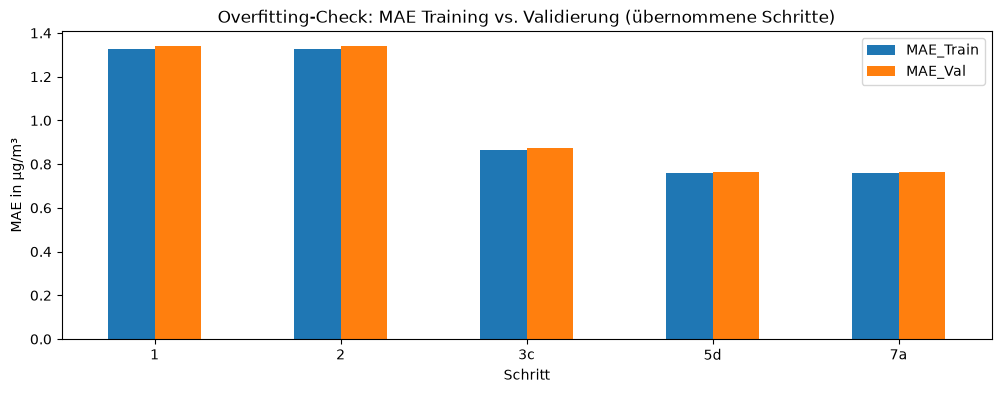

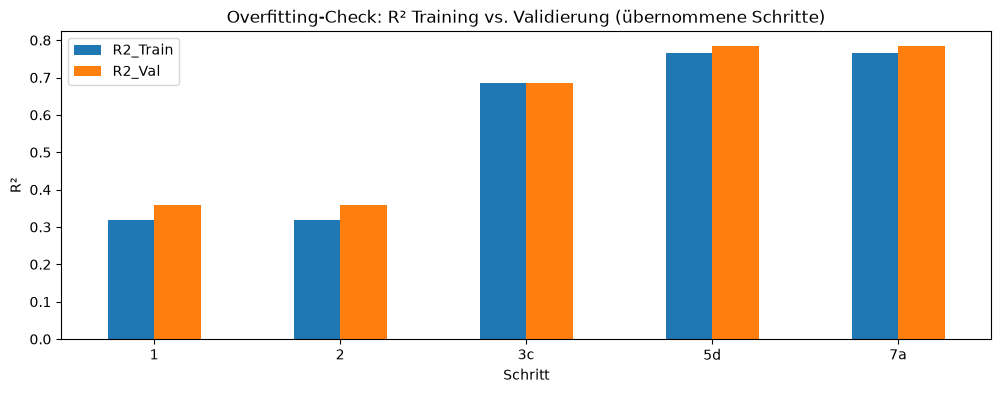

In [33]:
path_df = show(path).set_index("Schritt")
path_df["MAE_Abstand (Val - Train)"] = (path_df["MAE_Val"] - path_df["MAE_Train"]).round(4)
print(path_df[["Beschreibung", "Zeilen_Train", "Features", "MAE_Train", "MAE_Val",
               "MAE_Abstand (Val - Train)", "R2_Train", "R2_Val"]])

path_df[["MAE_Train", "MAE_Val"]].plot.bar(figsize=(12, 4), rot=0,
                                           title="Overfitting-Check: MAE Training vs. Validierung (übernommene Schritte)")
plt.ylabel("MAE in µg/m³")
plt.show()
path_df[["R2_Train", "R2_Val"]].plot.bar(figsize=(12, 4), rot=0,
                                         title="Overfitting-Check: R² Training vs. Validierung (übernommene Schritte)")
plt.ylabel("R²")
plt.show()

**Interpretation:** In allen übernommenen Schritten liegen Training und Validierung sehr nah beieinander. Der Abstand beim MAE schrumpft sogar von 0,016 (Baseline) auf 0,005 (finaler Stand), und R² ist auf Training und Validierung nahezu gleich. **Es gibt kein Overfitting.** Das ist bei einer linearen Regression mit 15 Features und 2.727 Trainingszeilen auch zu erwarten, weil das Modell nur 16 Parameter schätzt. Die einzige Variante mit deutlichem Abstand war 3f (MAE Training 0,754 vs. Validierung 0,879): Wer schwierige Trainingszeilen entfernt, bekommt einen geschönten Trainingswert.

Einschränkung: Training und Validierung stammen aus denselben Monaten, und durch den zufälligen Split landen benachbarte Stunden in beiden Datensätzen. Die Validierung ist dadurch eher optimistisch. Wie gut das Modell wirklich generalisiert, zeigt erst der Test (Abschnitt 10).

### 9.2 Verbesserung gegenüber der Baseline (Validierung)
Die folgenden Diagramme zeigen die absolute und relative Veränderung von MAE und R² gegenüber der Baseline, zuerst für den Weg der übernommenen Schritte, danach für alle kumulativen und isolierten Experimente.

         dMAE_abs  dMAE_rel_%  dR2_abs  dR2_rel_%
Schritt                                          
2         -0.0005     -0.0382   0.0004     0.1046
3c        -0.4666    -34.7739   0.3270    91.0677
5d        -0.5760    -42.9300   0.4262   118.6959
7a        -0.5760    -42.9300   0.4262   118.6959


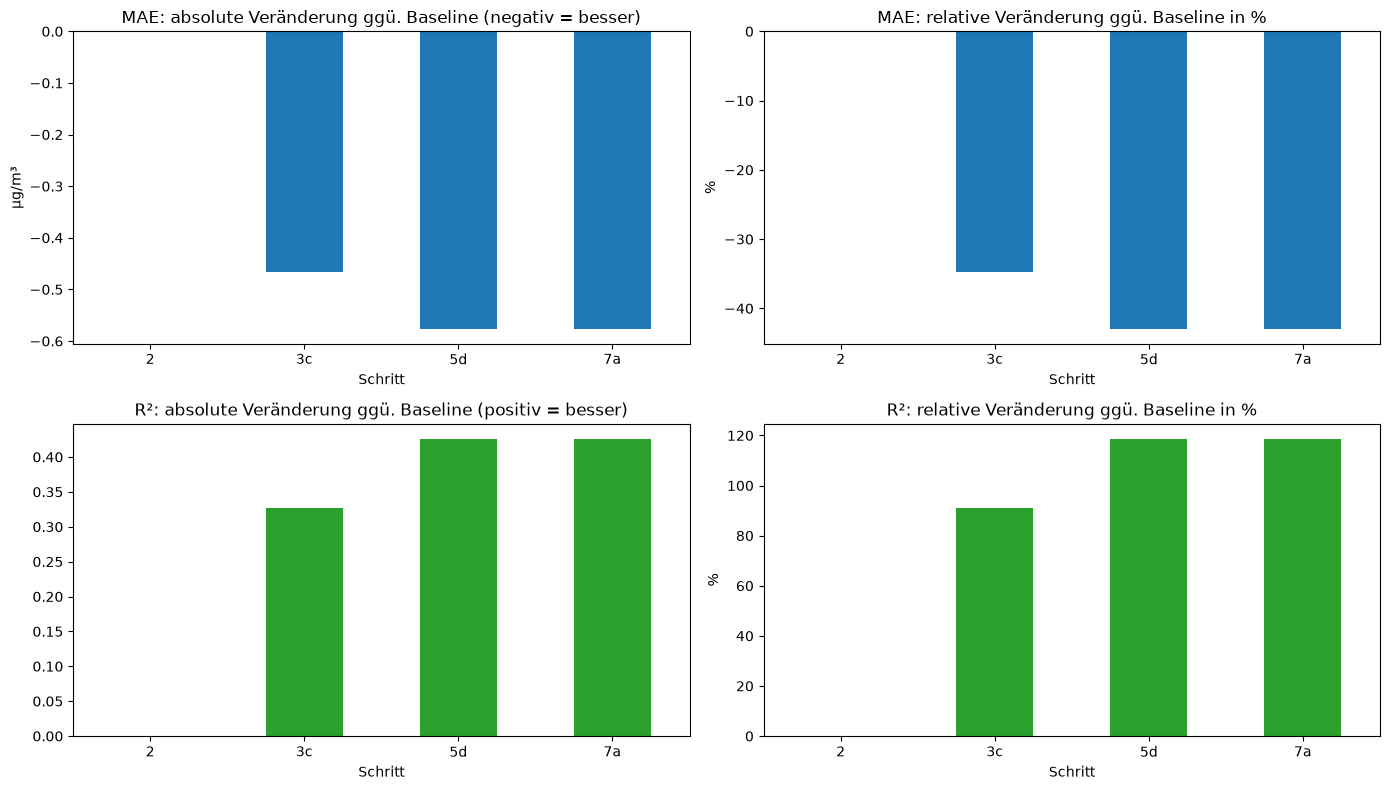

In [34]:
improvement = path_df.iloc[1:][["dMAE_abs", "dMAE_rel_%", "dR2_abs", "dR2_rel_%"]]
print(improvement.round(4))

fig, axs = plt.subplots(2, 2, figsize=(14, 8))
improvement["dMAE_abs"].plot.bar(ax=axs[0, 0], rot=0, color="tab:blue",
                                 title="MAE: absolute Veränderung ggü. Baseline (negativ = besser)")
axs[0, 0].set_ylabel("µg/m³")
improvement["dMAE_rel_%"].plot.bar(ax=axs[0, 1], rot=0, color="tab:blue",
                                   title="MAE: relative Veränderung ggü. Baseline in %")
axs[0, 1].set_ylabel("%")
improvement["dR2_abs"].plot.bar(ax=axs[1, 0], rot=0, color="tab:green",
                                title="R²: absolute Veränderung ggü. Baseline (positiv = besser)")
improvement["dR2_rel_%"].plot.bar(ax=axs[1, 1], rot=0, color="tab:green",
                                  title="R²: relative Veränderung ggü. Baseline in %")
axs[1, 1].set_ylabel("%")
plt.tight_layout()
plt.show()

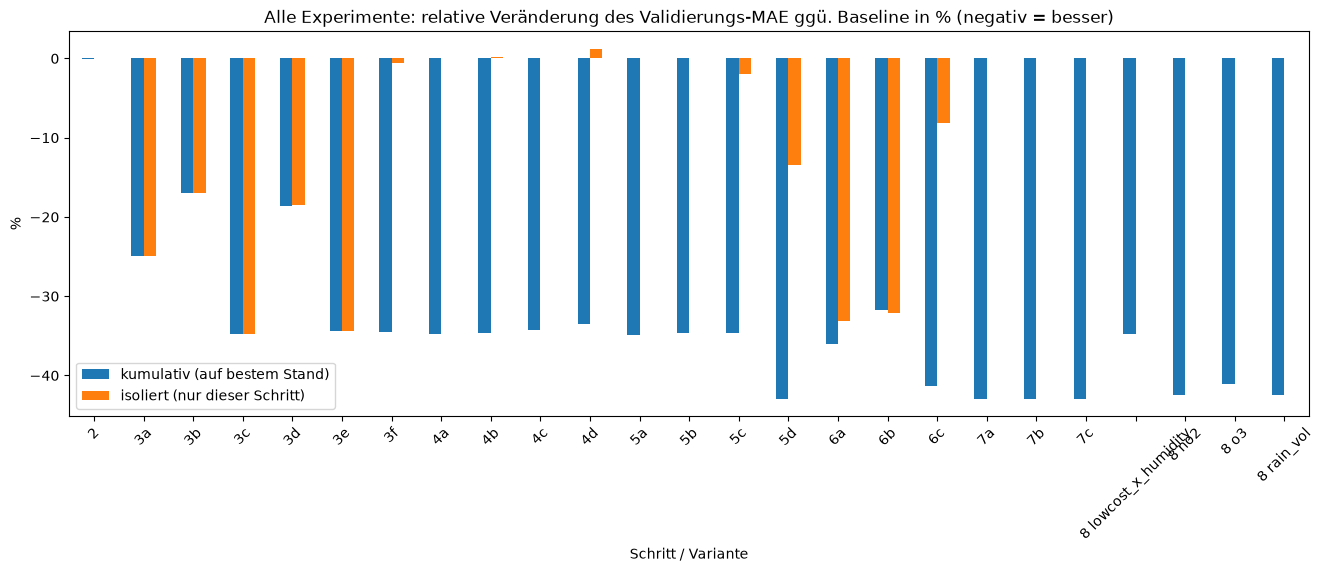

In [35]:
all_results = show(results)
cumulative = all_results[all_results["Art"] == "kumulativ"].set_index("Schritt")["dMAE_rel_%"]
isolated = all_results[all_results["Art"] == "isoliert"].set_index("Schritt")["dMAE_rel_%"]
comparison = pd.DataFrame({"kumulativ (auf bestem Stand)": cumulative, "isoliert (nur dieser Schritt)": isolated})
comparison.plot.bar(figsize=(16, 5), rot=45,
                    title="Alle Experimente: relative Veränderung des Validierungs-MAE ggü. Baseline in % (negativ = besser)")
plt.ylabel("%")
plt.xlabel("Schritt / Variante")
plt.show()

**Interpretation:**
- Der finale Stand verbessert den Validierungs-MAE gegenüber der Baseline um 0,576 µg/m³ (−42,9 %). R² steigt um 0,43 auf 0,785 (+119 %).
- Fast die gesamte Verbesserung stammt aus zwei Schritten: der Ausreißerbehandlung (3c, −34,8 %) und dem Interaktions-Feature (5d, weitere −8,2 Prozentpunkte). Plausibilität (2) und Skalierung (7a) ändern die Kennzahlen praktisch nicht.
- Das Diagramm aller Experimente zeigt, wie unterschiedlich isolierte und kumulative Effekte sein können. Die Verteilungs-Transformation 6a ist isoliert einer der stärksten Schritte (−33 %), auf dem besten Stand aber schädlich. Die Fehlwert-Strategien und die Varianten für `rain_vol` und Windrichtung wirken in beiden Fällen kaum.

## 10 Finaler Test

Jetzt wenden wir die **Baseline** und das **finale Modell** mit der finalen Data Preparation einmalig auf die Testdaten an:
- Alle 1.464 Testzeilen wurden mit den auf dem Training gelernten Parametern vorbereitet und erhalten eine Vorhersage. Es wird keine Zeile entfernt.
- 45 Testzeilen haben kein Referenz-Label. Für sie kann kein Fehler berechnet werden. MAE und R² werden deshalb über eine Maske (`notnull()`) auf den 1.419 Zeilen mit Label berechnet, ohne die übrigen Zeilen zu löschen.
- Beide Modelle werden auf genau den Trainingsdaten trainiert, mit denen sie auch validiert wurden.

In [36]:
def evaluate_test(name, train_df, test_df):
    """Trainiert die lineare Regression auf train_df und bewertet sie auf allen Testzeilen mit Label."""
    features = feature_columns(train_df)
    median = train_df[features].median()          # nur für die Baseline relevant (dort gibt es noch NaN)
    X_train = train_df[features].fillna(median)
    X_test = test_df[features].fillna(median)
    reg = linear_model.LinearRegression()
    reg.fit(X_train, train_df[LABEL])
    prediction = reg.predict(X_test)             # Vorhersage für ALLE Testzeilen
    has_label = test_df[LABEL].notnull()         # bewertbar sind nur Zeilen mit Referenzwert
    mae = mean_absolute_error(test_df[LABEL][has_label], prediction[has_label.values])
    r2 = reg.score(X_test[has_label], test_df[LABEL][has_label])
    with open(LOG_FILE, "a", encoding="utf-8") as log:
        log.write(f"10 | Test | {name} | Testzeilen gesamt {len(test_df)}, bewertet {has_label.sum()} | "
                  f"{len(features)} Features | MAE Test {mae:.4f} | R2 Test {r2:.4f}\n")
    return {"Modell": name, "MAE_Test": mae, "R2_Test": r2}, prediction


test_baseline, pred_baseline = evaluate_test("Baseline", train, test)
test_final, pred_final = evaluate_test("Finales Modell", train_cur, test_cur)
check_integrity(valid_cur, test_cur)

final_overview = pd.DataFrame({
    "MAE_Val": [BASELINE["MAE_Val"], current["MAE_Val"]],
    "MAE_Test": [test_baseline["MAE_Test"], test_final["MAE_Test"]],
    "R2_Val": [BASELINE["R2_Val"], current["R2_Val"]],
    "R2_Test": [test_baseline["R2_Test"], test_final["R2_Test"]]}, index=["Baseline", "Finales Modell"])
final_overview.round(4)

Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.


,MAE_Val,MAE_Test,R2_Val,R2_Test
Baseline,1.3417,2.2193,0.3590,-0.1453
Finales Modell,0.7657,1.5500,0.7852,0.4599


Veränderung finales Modell gegenüber Baseline (MAE: negativ = besser, R²: positiv = besser):
             MAE absolut  MAE relativ %  R² absolut
Validierung      -0.5760       -42.9300      0.4262
Test             -0.6693       -30.1582      0.6053


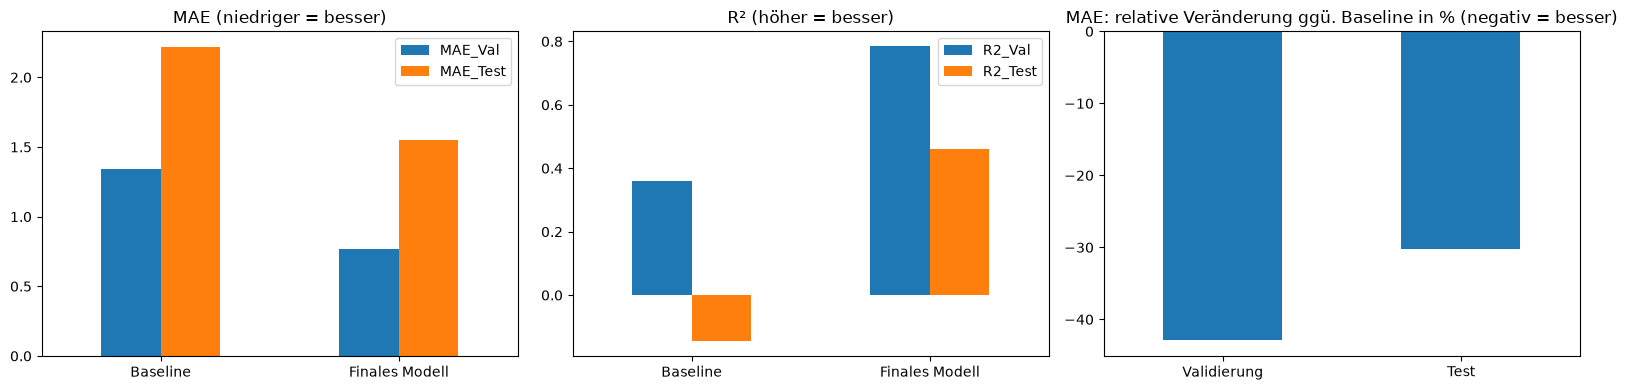

In [37]:
improvement_test = pd.DataFrame({
    "MAE absolut": [current["MAE_Val"] - BASELINE["MAE_Val"], test_final["MAE_Test"] - test_baseline["MAE_Test"]],
    "MAE relativ %": [(current["MAE_Val"] - BASELINE["MAE_Val"]) / BASELINE["MAE_Val"] * 100,
                      (test_final["MAE_Test"] - test_baseline["MAE_Test"]) / test_baseline["MAE_Test"] * 100],
    "R² absolut": [current["R2_Val"] - BASELINE["R2_Val"], test_final["R2_Test"] - test_baseline["R2_Test"]]},
    index=["Validierung", "Test"])
print("Veränderung finales Modell gegenüber Baseline (MAE: negativ = besser, R²: positiv = besser):")
print(improvement_test.round(4))

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
final_overview[["MAE_Val", "MAE_Test"]].plot.bar(ax=axs[0], rot=0, title="MAE (niedriger = besser)")
final_overview[["R2_Val", "R2_Test"]].plot.bar(ax=axs[1], rot=0, title="R² (höher = besser)")
improvement_test["MAE relativ %"].plot.bar(ax=axs[2], rot=0, color="tab:blue",
                                           title="MAE: relative Veränderung ggü. Baseline in % (negativ = besser)")
plt.tight_layout()
plt.show()

**Hinweis zur relativen R²-Veränderung:** Auf den Testdaten ist das R² der Baseline negativ. Eine relative Veränderung (Division durch einen negativen Wert nahe 0) wäre nicht interpretierbar. Für R² berichten wir auf dem Test deshalb nur die absolute Veränderung.

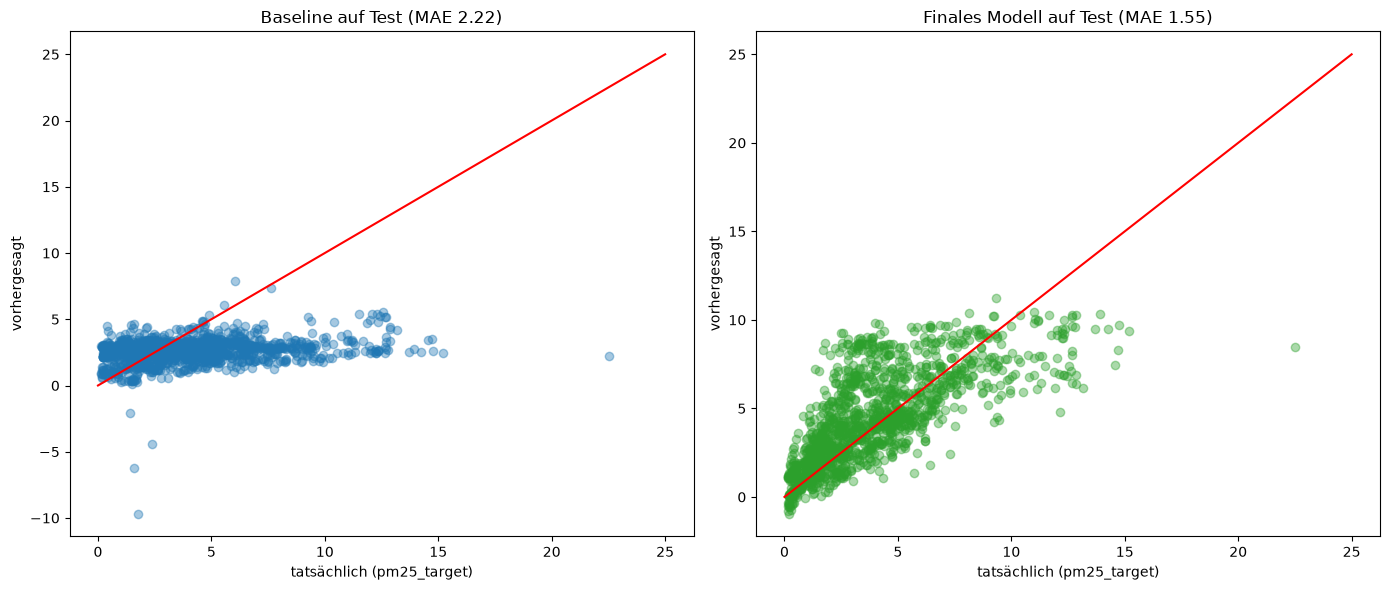

In [38]:
has_label = test[LABEL].notnull()
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].scatter(test.loc[has_label, LABEL], pred_baseline[has_label.values], alpha=0.4)
axs[0].plot([0, 25], [0, 25], color="red")
axs[0].set_title(f"Baseline auf Test (MAE {test_baseline['MAE_Test']:.2f})")
axs[0].set_xlabel("tatsächlich (pm25_target)")
axs[0].set_ylabel("vorhergesagt")
axs[1].scatter(test.loc[has_label, LABEL], pred_final[has_label.values], alpha=0.4, color="tab:green")
axs[1].plot([0, 25], [0, 25], color="red")
axs[1].set_title(f"Finales Modell auf Test (MAE {test_final['MAE_Test']:.2f})")
axs[1].set_xlabel("tatsächlich (pm25_target)")
axs[1].set_ylabel("vorhergesagt")
plt.tight_layout()
plt.show()

**Ergebnis auf den Testdaten:**
- Das finale Modell senkt den Test-MAE von 2,219 auf 1,550 µg/m³ (−30,2 %). R² steigt von −0,15 auf 0,46 (+0,61 absolut). Die Data Preparation verbessert das Modell also auch auf völlig neuen Daten deutlich. Zum Vergleich: In Aufgabe 1b war das ausgewählte Modell auf dem Test noch schlechter als seine Baseline.
- Die Baseline ist auf dem Test praktisch unbrauchbar. R² < 0 bedeutet, dass sie schlechter ist, als immer den Mittelwert vorherzusagen. Im Streudiagramm liegen ihre Vorhersagen fast unabhängig vom tatsächlichen Wert zwischen 1 und 5 µg/m³, und einzelne extreme Low-Cost-Werte führen zu Vorhersagen bis −10 µg/m³.
- Das finale Modell folgt der Diagonalen deutlich besser, unterschätzt aber hohe Werte: Über etwa 10 µg/m³ sagt es kaum noch etwas vorher.
- Der Test-MAE (1,55) liegt deutlich über dem Validierungs-MAE (0,77). Woran das liegt, untersuchen wir im nächsten Abschnitt.

### 10.1 Warum ist der Test-MAE höher als der Validierungs-MAE?
Die Testdaten wurden nicht zur Auswahl genutzt. Mit ihnen können wir aber erklären, woher der Unterschied zwischen Validierung und Test kommt. Wir vergleichen dazu den Fehler des finalen Modells in verschiedenen Gruppen der Testdaten.

In [39]:
abs_error = (test[LABEL] - pred_final).abs()      # NaN für Zeilen ohne Label, wird bei mean() ignoriert

print("MAE finales Modell nach Monat:")
print(abs_error.groupby(test["year_month"]).mean().round(3))

weather_missing = test["temperature"].isnull()
print("\nMAE finales Modell nach Verfügbarkeit der Wetterdaten im Original (True = Wetterdaten fehlten, wurden imputiert):")
print(abs_error.groupby(weather_missing).mean().round(3))

# Liegt der Low-Cost-Wert über der IQR-Grenze der Trainingsdaten (wurde also in Schritt 3 verändert)?
q1, q3 = train["pm25_lowcost"].quantile(0.25), train["pm25_lowcost"].quantile(0.75)
lowcost_fence = q3 + 1.5 * (q3 - q1)
above_train = (train["pm25_lowcost"] > lowcost_fence).sum() / train["pm25_lowcost"].notnull().sum() * 100
above_test = (test["pm25_lowcost"] > lowcost_fence).sum() / test["pm25_lowcost"].notnull().sum() * 100
print(f"\nAnteil Low-Cost-Werte über der Trainings-IQR-Grenze ({lowcost_fence:.2f} µg/m³): "
      f"Training {above_train:.1f} %, Test {above_test:.1f} %")
print("MAE finales Modell nach Low-Cost-Wert über der Grenze (True = Wert wurde gekappt):")
print(abs_error.groupby(test["pm25_lowcost"] > lowcost_fence).mean().round(3))

print("\nVerteilungen Training (Juni-Oktober) vs. Test (November-Dezember):")
shift = pd.DataFrame({"Training Mittelwert": df[["temperature", "relative_humidity", "pm25_lowcost", LABEL]].mean(),
                      "Test Mittelwert": test[["temperature", "relative_humidity", "pm25_lowcost", LABEL]].mean(),
                      "Training Max": df[["temperature", "relative_humidity", "pm25_lowcost", LABEL]].max(),
                      "Test Max": test[["temperature", "relative_humidity", "pm25_lowcost", LABEL]].max()})
print(shift.round(2))

MAE finales Modell nach Monat:
year_month
2024-11    1.478
2024-12    1.615
Name: pm25_target, dtype: float64

MAE finales Modell nach Verfügbarkeit der Wetterdaten im Original (True = Wetterdaten fehlten, wurden imputiert):
temperature
False    1.669
True     1.498
Name: pm25_target, dtype: float64

Anteil Low-Cost-Werte über der Trainings-IQR-Grenze (9.69 µg/m³): Training 7.7 %, Test 23.5 %
MAE finales Modell nach Low-Cost-Wert über der Grenze (True = Wert wurde gekappt):
pm25_lowcost
False    1.171
True     2.791
Name: pm25_target, dtype: float64

Verteilungen Training (Juni-Oktober) vs. Test (November-Dezember):
                   Training Mittelwert  Test Mittelwert  Training Max  \
temperature                      17.77             5.82         33.17   
relative_humidity                73.82            82.04         96.30   
pm25_lowcost                      5.52            11.92        595.53   
pm25_target                       3.34             3.91         15.56   

          

**Interpretation:** Die Lücke zwischen Validierung und Test hat vor allem eine Ursache, den **Saison-Shift**:
- Die Testdaten stammen aus November und Dezember, die Trainingsdaten aus Juni bis Oktober. Im Winter ist es kälter (im Mittel 5,8 °C statt 17,8 °C) und feuchter (82 % statt 74 %). Der Low-Cost-Sensor zeigt im Mittel mehr als doppelt so hohe Werte (11,9 statt 5,5 µg/m³), und auch das Referenzgerät misst höhere Spitzen (bis 22,5 statt 15,6 µg/m³).
- **Hauptursache sind Werte außerhalb des Trainingsbereichs:** Im Test liegen 23,5 % der Low-Cost-Werte über der IQR-Grenze aus dem Training (Training: 7,7 %). Diese Werte wurden in Schritt 3 auf den Trainingswert gekappt. In diesen Zeilen liegt der MAE bei 2,79 µg/m³, in allen übrigen bei 1,17 µg/m³. Vermutlich können die Grenzen aus den Sommerdaten im Winter nicht mehr zwischen Feuchte-Artefakten und echten hohen Feinstaubwerten unterscheiden. Das erklärt auch, warum das Modell hohe Werte unterschätzt.
- **Die vielen imputierten Wetterdaten sind dagegen nicht die Hauptursache:** Zeilen, in denen die Wetterdaten ersetzt wurden, haben sogar einen etwas niedrigeren MAE (1,50) als Zeilen mit echten Wetterdaten (1,67).
- Der Dezember (MAE 1,62) ist etwas schwieriger als der November (1,48).
- Hinzu kommt der zufällige Split: Die Validierung stammt aus denselben Monaten wie das Training und ist dadurch optimistischer als ein Test in einer neuen Jahreszeit.

**Konsequenzen für Aufgabe 3:** Nichtlineare Verfahren (z. B. polynomiale Regression oder Regressionsbäume) können den Feuchte-Effekt und die Sättigung eventuell besser abbilden. Außerdem sollten die Capping-Grenzen für `pm25_lowcost` kritisch geprüft werden, z. B. nur bei hoher Luftfeuchte kappen, weil hohe Low-Cost-Werte im Winter teilweise echt sind.

## 11 Export und Learnings

### 11.1 Export der vorbereiteten Datensätze
Die finale Data Preparation wird als CSV in den Ordner `src/Data/` exportiert. Aufgabe 3 baut auf diesen Dateien auf:
- `pm25_train_prepared.csv`, `pm25_validation_prepared.csv`, `pm25_test_prepared.csv`
- Spalten: `timestamp` (nur zur Nachvollziehbarkeit, kein Feature), alle finalen Features, `pm25_target` (unverändert)
- Der Testdatensatz enthält alle 1.464 Zeilen, auch die 45 Zeilen ohne Label.
- Zusätzlich: `task2_evaluation.csv` (alle Experimente) und das Log-File `task2_log.txt`.

In [40]:
final_features = feature_columns(train_cur)
export_cols = ["timestamp"] + final_features + [LABEL]

train_cur[export_cols].to_csv(DATA_DIR + "pm25_train_prepared.csv", index=False)
valid_cur[export_cols].to_csv(DATA_DIR + "pm25_validation_prepared.csv", index=False)
test_cur[export_cols].to_csv(DATA_DIR + "pm25_test_prepared.csv", index=False)
show(results).to_csv(DATA_DIR + "task2_evaluation.csv", index=False)

check_integrity(valid_cur, test_cur)
for name, data in [("Training", train_cur), ("Validierung", valid_cur), ("Test", test_cur)]:
    print(f"{name}: {data[export_cols].shape[0]} Zeilen, {len(final_features)} Features, "
          f"fehlende Feature-Werte: {data[final_features].isnull().sum().sum()}, fehlende Labels: {data[LABEL].isnull().sum()}")
print("\nFinale Features:", final_features)

Integritätsprüfung bestanden: Validierung 682 Zeilen, Test 1464 Zeilen, Labels unverändert.
Training: 2727 Zeilen, 15 Features, fehlende Feature-Werte: 0, fehlende Labels: 0
Validierung: 682 Zeilen, 15 Features, fehlende Feature-Werte: 0, fehlende Labels: 0
Test: 1464 Zeilen, 15 Features, fehlende Feature-Werte: 0, fehlende Labels: 45

Finale Features: ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad', 'lowcost_x_humidity']


In [41]:
# Kontrolle: Inhalt des Log-Files
with open(LOG_FILE, encoding="utf-8") as log:
    print(log.read())

Log Aufgabe 2 - Data Preparation, Modell: lineare Regression
Split wie Aufgabe 1: dropna(Label), train_test_split(test_size=0.20, random_state=42)
Spalten: Schritt | Art | Beschreibung (was wurde angepasst) | Zeilen Train | Anzahl Features | MAE Train | MAE Val | R2 Train | R2 Val | dMAE Val vs. Baseline
1 | Baseline | Originaldaten, 14 numerische Features, NaN -> Trainings-Median | 2727 | 14 | 1.3261 | 1.3417 | 0.3183 | 0.3590 | +0.0000
2 | kumulativ | negative Konzentrationen auf 0 gesetzt (clip) | 2727 | 14 | 1.3257 | 1.3412 | 0.3186 | 0.3594 | -0.0005
ENTSCHEIDUNG Schritt 2 (Plausibilität): übernommen wird 2 'negative Konzentrationen auf 0 gesetzt (clip)' (MAE Val 1.3417 -> 1.3412, R2 Val 0.3590 -> 0.3594)
3a | kumulativ | Ausreißer: IQR-Regel -> NaN (danach Median) | 2727 | 14 | 0.9877 | 1.0064 | 0.5342 | 0.5643 | -0.3353
3a | isoliert | Ausreißer: IQR-Regel -> NaN (danach Median) | 2727 | 14 | 0.9884 | 1.0075 | 0.5339 | 0.5635 | -0.3342
3b | kumulativ | Ausreißer: 3-Sigma-Regel -

### 11.2 Ergebnis und Learnings aus Aufgabe 2

**Ergebnis**

| Kennzahl | Baseline | Finales Modell | Veränderung |
|---|---|---|---|
| MAE Validierung | 1,342 | 0,766 | −42,9 % |
| R² Validierung | 0,359 | 0,785 | +0,43 |
| MAE Test | 2,219 | 1,550 | −30,2 % |
| R² Test | −0,145 | 0,460 | +0,61 |

**Finale Data Preparation** (in dieser Reihenfolge, alle Parameter aus den Trainingsdaten gelernt):
1. Negative Konzentrationen (`no`, `o3`) auf 0 setzen.
2. Ausreißer in `pm25_lowcost`, `no`, `no2`, `black_carbon`, `ufp` und `co2` mit der IQR-Regel erkennen und durch das 5. bzw. 95. Perzentil ersetzen.
3. Fehlende Werte mit dem Median der Trainingsdaten ersetzen.
4. Neues Feature `lowcost_x_humidity = pm25_lowcost × relative_humidity`.
5. StandardScaler auf allen 15 Features.

Verworfen wurden (jeweils auf der Validierung schlechter): Entfernen von Label-Ausreißern, Mittelwert-, Regressions-Imputation und Listwise Deletion, Umbau von `rain_vol`, zyklische Windrichtung, Power- und Quantile-Transformation sowie das Entfernen einzelner Features.

**Fachliche Learnings**
- **Ausreißer waren das Hauptproblem:** Die Feuchte-Artefakte des Low-Cost-Sensors haben den eigentlich engen Zusammenhang zum Referenzgerät verdeckt (r = 0,08 → 0,61). Wichtig ist, wie man sie behandelt: Kappen erhält die Information „hoch“, Ersetzen durch den Median nicht.
- **Domänenwissen schlägt Trial-and-Error:** Das Interaktions-Feature mit der Luftfeuchte entstand aus einer Beobachtung in den Daten und dem Messprinzip des Sensors. Es brachte den zweitgrößten Sprung.
- **Nicht jede Lehrbuch-Transformation hilft:** Normalverteilte Features sind keine Voraussetzung der linearen Regression. Zyklische Kodierung und Regen pro Stunde sind fachlich sauber, bringen hier aber keinen messbaren Nutzen.
- **Schritte überlagern sich:** Die Verteilungs-Transformation ist isoliert stark, nach dem Kappen aber schädlich. Deshalb bewerten wir jeden Schritt isoliert und kumulativ.
- **Schwache Korrelation heißt nicht nutzlos, hoher VIF heißt nicht entfernen:** `o3` hilft trotz r ≈ 0, und der hohe VIF der Interaktion ist strukturell bedingt.
- **Validierung ist nicht gleich Test:** Durch den Saison-Shift liegen im Winter fast ein Viertel der Low-Cost-Werte außerhalb des Trainingsbereichs. Das erklärt den Großteil der Lücke zwischen Validierungs- und Test-MAE.

**Learnings aus dem Coding**
- Gleicher Split und gleicher `random_state` machen die Anknüpfung an Aufgabe 1 exakt reproduzierbar (Baseline = Modell mit allen Features aus Aufgabe 1b).
- Parameter dürfen nur aus den Trainingsdaten gelernt werden. Die Ausreißer-Klassen aus dem Kurs berechnen ihre Grenzen in `transform()` jedes Mal neu aus den übergebenen Daten. Validierung und Test hätten dann ihre eigenen Grenzen bestimmt. Wir berechnen die Grenzen deshalb einmal aus dem Training.
- Wiederverwendbare Hilfsfunktionen (`evaluate`, `decide`, `check_integrity`) machen über 40 Experimente vergleichbar und dokumentieren sie automatisch im Log-File.
- Automatische Prüfungen mit `assert` stellen sicher, dass in Validierung und Test keine Zeile verloren geht und kein Label verändert wird.
- Testzeilen ohne Label werden nicht gelöscht, sondern bei der Bewertung über eine Maske (`notnull()`) ausgeblendet.
- Zeitabhängige Features (Regen pro Stunde mit `shift`) müssen auf den chronologisch sortierten Originaldaten berechnet werden, weil der zufällige Split die Zeilen mischt.
- Eine feste Entscheidungsregel (MAE sinkt und R² wird nicht schlechter) verhindert reines Trial-and-Error. Bewusste Ausnahmen wie die Skalierung werden begründet und im Log-File protokolliert.

**Ausblick auf Aufgabe 3**
- Aufgabe 3 startet mit den exportierten Dateien `pm25_train_prepared.csv`, `pm25_validation_prepared.csv` und `pm25_test_prepared.csv`.
- Nichtlineare Verfahren (polynomiale Regression, Regressionsbäume) könnten den Feuchte-Effekt und die Sättigung bei hohen Werten besser abbilden.
- Die Capping-Grenzen für `pm25_lowcost` sollten kritisch geprüft werden, weil hohe Low-Cost-Werte im Winter teilweise echt sind.
- Eine zeitliche Aufteilung (z. B. Oktober als Validierung) würde die Testleistung realistischer vorhersagen als der zufällige Split. Für die Vergleichbarkeit mit Aufgabe 1 haben wir den Split beibehalten.
- **Nicht umgesetzt: Uhrzeit-Feature.** Der `timestamp` enthält die Uhrzeit, und Feinstaub folgt einem Tagesrhythmus (Berufsverkehr, nächtliche Inversionswetterlagen). Ein Stunden-Feature (zyklisch kodiert wie die Windrichtung) könnte das Modell verbessern. Wir haben es bewusst nicht verwendet, weil die dafür nötige Funktion (`.dt.hour`) in den Kurs-Skripten nicht vorkommt.